
# 07. Dynamic Risk Trajectories

## Project
Dynamic and Explainable Credit Risk Early-Warning System with Portfolio Stress Testing

## 1. Research Objective

This notebook develops a borrower-level dynamic credit-risk monitoring framework using the previously trained Histogram Gradient Boosting model.

The objective is to calculate monthly six-month-forward-looking delinquency probabilities and track how predicted risk evolves across successive reporting periods.

## 2. Research Questions

1. How does predicted delinquency risk change over time for individual borrowers?
2. Which borrowers exhibit increasing or deteriorating risk?
3. Which borrowers remain persistently high-risk?
4. Which borrowers show improving risk?
5. Can successive risk scores support an operational early-warning mechanism?

## 3. Methodology

- Reuse the selected and frozen HGB model.
- Generate monthly probabilities for validation and test observations.
- Preserve loan identifiers and reporting chronology.
- Apply the validation-selected operating threshold of 0.58 without retuning it on the test set.
- Calculate month-to-month risk changes.
- Identify persistent and deteriorating risk patterns.
- Evaluate trajectory behaviour against subsequently observed outcomes.

## 4. Methodological Controls

- No model retraining.
- No use of future observations to generate current-month predictions.
- No test-set threshold tuning.
- No modification of the original 129-feature model schema.
- Distinguish predicted risk from realised delinquency.


In [1]:

# ============================================================
# SECTION 1: ENVIRONMENT AND PROJECT CONFIGURATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import duckdb
import joblib
import gc
import json
import time
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

# Project directory
PROJECT_DIR = Path(
    r"C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning"
)

# Main directories
MODELS_DIR = PROJECT_DIR / "models"

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

PREPROCESSING_DIR = (
    PROCESSED_DIR / "model_preprocessing"
)

TRANSFORMED_DIR = (
    PREPROCESSING_DIR / "transformed_datasets"
)

# Input datasets
VALIDATION_FILE = (
    TRANSFORMED_DIR / "validation_transformed.parquet"
)

TEST_FILE = (
    TRANSFORMED_DIR / "test_transformed.parquet"
)

HGB_MODEL_FILE = (
    MODELS_DIR / "hist_gradient_boosting_baseline.joblib"
)

# Output directories
DYNAMIC_OUTPUT_DIR = (
    PROCESSED_DIR / "dynamic_risk"
)

DYNAMIC_FIGURES_DIR = (
    PROJECT_DIR / "figures" / "dynamic_risk"
)

DYNAMIC_OUTPUT_DIR.mkdir(
    parents=True, exist_ok=True
)

DYNAMIC_FIGURES_DIR.mkdir(
    parents=True, exist_ok=True
)

# Previously selected validation threshold
WARNING_THRESHOLD = 0.58

# Batch processing
BATCH_SIZE = 25000

print("PROJECT:", PROJECT_DIR)
print("DYNAMIC RISK OUTPUT:", DYNAMIC_OUTPUT_DIR)
print("FIGURES OUTPUT:", DYNAMIC_FIGURES_DIR)
print("WARNING THRESHOLD:", WARNING_THRESHOLD)
print("BATCH SIZE:", BATCH_SIZE)

print("\nENVIRONMENT INITIALISED")


PROJECT: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning
DYNAMIC RISK OUTPUT: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\data\processed\dynamic_risk
FIGURES OUTPUT: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\figures\dynamic_risk
WARNING THRESHOLD: 0.58
BATCH SIZE: 25000

ENVIRONMENT INITIALISED


In [2]:

# ============================================================
# SECTION 2: INPUT AND MODEL VERIFICATION
# ============================================================

required_files = {
    "HGB model": HGB_MODEL_FILE,
    "Validation dataset": VALIDATION_FILE,
    "Test dataset": TEST_FILE
}

for name, path in required_files.items():

    print(
        f"{name:25}:",
        "PASS" if path.exists() else "MISSING"
    )

assert all(
    path.exists() for path in required_files.values()
), "Required input file missing."

# Load frozen HGB model
hgb_model = joblib.load(HGB_MODEL_FILE)

# Exact feature order from training
predictor_columns = list(
    hgb_model.feature_names_in_
)

print("\nMODEL:", type(hgb_model))
print("MODEL FEATURES:", hgb_model.n_features_in_)
print("MODEL ITERATIONS:", hgb_model.n_iter_)
print("FEATURE ORDER AVAILABLE:", 
      hasattr(hgb_model, "feature_names_in_"))

assert hgb_model.n_features_in_ == 129
assert len(predictor_columns) == 129

print("\nHGB MODEL VERIFICATION: PASS")


HGB model                : PASS
Validation dataset       : PASS
Test dataset             : PASS

MODEL: <class 'sklearn.ensemble._hist_gradient_boosting.gradient_boosting.HistGradientBoostingClassifier'>
MODEL FEATURES: 129
MODEL ITERATIONS: 200
FEATURE ORDER AVAILABLE: True

HGB MODEL VERIFICATION: PASS


In [3]:

# ============================================================
# SECTION 3: TEMPORAL DATASET SCHEMA VERIFICATION
# ============================================================

con = duckdb.connect()

validation_schema = con.execute(
    f"""
    DESCRIBE
    SELECT * FROM read_parquet(
        '{VALIDATION_FILE.as_posix()}'
    )
    """
).fetchdf()

test_schema = con.execute(
    f"""
    DESCRIBE
    SELECT * FROM read_parquet(
        '{TEST_FILE.as_posix()}'
    )
    """
).fetchdf()

con.close()

validation_columns = (
    validation_schema["column_name"].tolist()
)

test_columns = (
    test_schema["column_name"].tolist()
)

CORE_COLUMNS = [
    "loan_id",
    "reporting_date",
    "target_6m"
]

validation_predictors = [
    col for col in validation_columns
    if col not in CORE_COLUMNS
]

test_predictors = [
    col for col in test_columns
    if col not in CORE_COLUMNS
]

print("VALIDATION TOTAL COLUMNS:", len(validation_columns))
print("TEST TOTAL COLUMNS:", len(test_columns))

print(
    "VALIDATION FEATURE COUNT:",
    len(validation_predictors)
)

print(
    "TEST FEATURE COUNT:",
    len(test_predictors)
)

print(
    "VALIDATION MODEL FEATURE ORDER:",
    validation_predictors == predictor_columns
)

print(
    "TEST MODEL FEATURE ORDER:",
    test_predictors == predictor_columns
)

assert validation_predictors == predictor_columns
assert test_predictors == predictor_columns

assert all(
    col in validation_columns
    for col in CORE_COLUMNS
)

assert all(
    col in test_columns
    for col in CORE_COLUMNS
)

print("\nTEMPORAL DATASET SCHEMA AUDIT: PASS")


VALIDATION TOTAL COLUMNS: 132
TEST TOTAL COLUMNS: 132
VALIDATION FEATURE COUNT: 129
TEST FEATURE COUNT: 129
VALIDATION MODEL FEATURE ORDER: True
TEST MODEL FEATURE ORDER: True

TEMPORAL DATASET SCHEMA AUDIT: PASS



## 4. Monthly Borrower Risk Scoring

The frozen Histogram Gradient Boosting model is applied to the validation and test datasets to calculate six-month-forward-looking delinquency probabilities for each borrower-month observation.

Batch-wise inference is used to manage memory requirements.

For every observation, the system generates:

- Predicted six-month delinquency probability.
- Binary early-warning flag using the validation-selected threshold of 0.58.
- Borrower identifier and reporting date.
- Actual target for subsequent evaluation.

The model and threshold remain unchanged throughout test-period scoring.


In [4]:
# ============================================================
# SECTION 4B: BATCH-WISE HGB RISK SCORING
# ============================================================

import pyarrow as pa
import pyarrow.parquet as pq
import time
import gc
import numpy as np
import pandas as pd
import duckdb

def generate_dynamic_risk(
    input_file,
    output_file,
    dataset_label
):

    input_file = Path(input_file)
    output_file = Path(output_file)

    if output_file.exists():
        raise FileExistsError(
            f"Output already exists: {output_file}. "
            "Do not overwrite without reviewing it."
        )

    print("\n" + "=" * 65)
    print("STARTING:", dataset_label)
    print("=" * 65)

    feature_sql = ", ".join(
        '"' + col.replace('"', '""') + '"'
        for col in predictor_columns
    )

    query = f"""
        SELECT
            loan_id,
            reporting_date,
            target_6m,
            {feature_sql}
        FROM read_parquet('{input_file.as_posix()}')
    """

    con = duckdb.connect()

    reader = con.execute(query).fetch_record_batch(
        rows_per_batch=BATCH_SIZE
    )

    writer = None
    total_rows = 0
    total_events = 0
    total_flags = 0
    min_probability = 1.0
    max_probability = 0.0

    start_time = time.time()

    try:

        for batch_number, record_batch in enumerate(
            reader, start=1
        ):

            batch_df = record_batch.to_pandas()

            # Preserve the exact training feature order
            X_batch = batch_df[
                predictor_columns
            ].astype(np.float32)

            # Predict probability of class 1
            probabilities = hgb_model.predict_proba(
                X_batch
            )[:, 1]

            # Apply the previously selected threshold
            warning_flags = (
                probabilities >= WARNING_THRESHOLD
            ).astype(np.int8)

            # Construct output
            output_df = pd.DataFrame({
                "loan_id": batch_df["loan_id"].values,
                "reporting_date": pd.to_datetime(
                    batch_df["reporting_date"]
                ),
                "target_6m": batch_df[
                    "target_6m"
                ].astype(np.int8).values,
                "predicted_probability": probabilities,
                "warning_flag_058": warning_flags
            })

            # Convert to Arrow and write incrementally
            table = pa.Table.from_pandas(
                output_df,
                preserve_index=False
            )

            if writer is None:
                writer = pq.ParquetWriter(
                    output_file,
                    table.schema,
                    compression="zstd"
                )

            writer.write_table(table)

            # Running totals
            rows = len(output_df)

            total_rows += rows
            total_events += int(
                output_df["target_6m"].sum()
            )
            total_flags += int(
                output_df["warning_flag_058"].sum()
            )

            min_probability = min(
                min_probability,
                float(probabilities.min())
            )

            max_probability = max(
                max_probability,
                float(probabilities.max())
            )

            if batch_number % 5 == 0:
                elapsed = time.time() - start_time

                print(
                    f"Batches: {batch_number} | "
                    f"Rows: {total_rows:,} | "
                    f"Elapsed: {elapsed/60:.2f} min"
                )

            del batch_df, X_batch, output_df, table
            gc.collect()

    finally:

        if writer is not None:
            writer.close()

        con.close()

    elapsed = time.time() - start_time

    result = {
        "dataset": dataset_label,
        "observations": total_rows,
        "events": total_events,
        "non_events": total_rows - total_events,
        "warning_flags": total_flags,
        "warning_rate": total_flags / total_rows,
        "event_rate": total_events / total_rows,
        "minimum_probability": min_probability,
        "maximum_probability": max_probability,
        "execution_minutes": elapsed / 60,
        "output_file": str(output_file)
    }

    print("\nSCORING COMPLETED")
    print(json.dumps(result, indent=2))

    return result

In [5]:
# ============================================================
# SECTION 4C: GENERATE VALIDATION AND TEST RISK SCORES
# ============================================================

VALIDATION_RISK_FILE = (
    DYNAMIC_OUTPUT_DIR /
    "validation_dynamic_risk.parquet"
)

TEST_RISK_FILE = (
    DYNAMIC_OUTPUT_DIR /
    "test_dynamic_risk.parquet"
)

# Validation scoring
validation_result = generate_dynamic_risk(
    input_file=VALIDATION_FILE,
    output_file=VALIDATION_RISK_FILE,
    dataset_label="VALIDATION 2023"
)

# Test scoring
test_result = generate_dynamic_risk(
    input_file=TEST_FILE,
    output_file=TEST_RISK_FILE,
    dataset_label="OUT-OF-TIME TEST 2024-2025"
)

# Save scoring summary
scoring_summary = {
    "warning_threshold": WARNING_THRESHOLD,
    "model": "Histogram Gradient Boosting",
    "validation": validation_result,
    "test": test_result
}

with open(
    DYNAMIC_OUTPUT_DIR / "dynamic_scoring_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(scoring_summary, f, indent=2)

print("\nBOTH DATASETS SCORED SUCCESSFULLY")


STARTING: VALIDATION 2023


C:\Users\madhu\AppData\Local\Temp\ipykernel_25744\1877540404.py:48: DeprecationWarning: fetch_record_batch() is deprecated, use to_arrow_reader() instead.
  reader = con.execute(query).fetch_record_batch(


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Batches: 5 | Rows: 125,000 | Elapsed: 0.29 min
Batches: 10 | Rows: 250,000 | Elapsed: 0.39 min
Batches: 15 | Rows: 375,000 | Elapsed: 0.58 min
Batches: 20 | Rows: 500,000 | Elapsed: 0.70 min
Batches: 25 | Rows: 625,000 | Elapsed: 0.81 min
Batches: 30 | Rows: 750,000 | Elapsed: 0.91 min
Batches: 35 | Rows: 875,000 | Elapsed: 1.00 min
Batches: 40 | Rows: 1,000,000 | Elapsed: 1.11 min
Batches: 45 | Rows: 1,125,000 | Elapsed: 1.22 min
Batches: 50 | Rows: 1,250,000 | Elapsed: 1.33 min
Batches: 55 | Rows: 1,375,000 | Elapsed: 1.43 min
Batches: 60 | Rows: 1,500,000 | Elapsed: 1.52 min

SCORING COMPLETED
{
  "dataset": "VALIDATION 2023",
  "observations": 1569879,
  "events": 50952,
  "non_events": 1518927,
  "warning_flags": 112474,
  "warning_rate": 0.07164501213150823,
  "event_rate": 0.03245600457105293,
  "minimum_probability": 0.004347945208688153,
  "maximum_probability": 0.975342989173446,
  "execution_minutes": 1.584727450211843,
  "output_file": "C:\\Users\\madhu\\OneDrive\\Desktop\\

C:\Users\madhu\AppData\Local\Temp\ipykernel_25744\1877540404.py:48: DeprecationWarning: fetch_record_batch() is deprecated, use to_arrow_reader() instead.
  reader = con.execute(query).fetch_record_batch(


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Batches: 5 | Rows: 125,000 | Elapsed: 0.18 min
Batches: 10 | Rows: 250,000 | Elapsed: 0.31 min
Batches: 15 | Rows: 375,000 | Elapsed: 0.41 min
Batches: 20 | Rows: 500,000 | Elapsed: 0.50 min
Batches: 25 | Rows: 625,000 | Elapsed: 0.60 min
Batches: 30 | Rows: 750,000 | Elapsed: 0.71 min
Batches: 35 | Rows: 875,000 | Elapsed: 0.82 min
Batches: 40 | Rows: 1,000,000 | Elapsed: 0.92 min
Batches: 45 | Rows: 1,125,000 | Elapsed: 1.01 min
Batches: 50 | Rows: 1,250,000 | Elapsed: 1.12 min
Batches: 55 | Rows: 1,375,000 | Elapsed: 1.22 min
Batches: 60 | Rows: 1,500,000 | Elapsed: 1.32 min
Batches: 65 | Rows: 1,625,000 | Elapsed: 1.46 min
Batches: 70 | Rows: 1,750,000 | Elapsed: 1.57 min
Batches: 75 | Rows: 1,875,000 | Elapsed: 1.67 min
Batches: 80 | Rows: 2,000,000 | Elapsed: 1.77 min
Batches: 85 | Rows: 2,125,000 | Elapsed: 1.87 min
Batches: 90 | Rows: 2,250,000 | Elapsed: 1.98 min
Batches: 95 | Rows: 2,375,000 | Elapsed: 2.07 min
Batches: 100 | Rows: 2,483,739 | Elapsed: 2.21 min

SCORING COMPL


## 5. Dynamic Risk Dataset Validation

The generated risk-scoring datasets are audited to ensure that:

- Every source observation is represented exactly once.
- No rows are lost during inference.
- Predicted probabilities are finite and within [0, 1].
- Warning flags agree with the selected 0.58 threshold.
- Event counts match the original transformed datasets.
- Reporting dates remain within the expected temporal windows.


In [6]:
# ============================================================
# SECTION 5A: DYNAMIC RISK OUTPUT AUDIT
# ============================================================

con = duckdb.connect()

audit_files = {
    "VALIDATION": (
        VALIDATION_FILE,
        VALIDATION_RISK_FILE,
        1569879,
        50952
    ),
    "TEST": (
        TEST_FILE,
        TEST_RISK_FILE,
        2483739,
        76861
    )
}

for label, (
    source_file,
    output_file,
    expected_rows,
    expected_events
) in audit_files.items():

    print("\n", "=" * 60)
    print(label, "AUDIT")
    print("=" * 60)

    source_stats = con.execute(
        f"""
        SELECT
            COUNT(*) AS observations,
            SUM(target_6m) AS events
        FROM read_parquet('{source_file.as_posix()}')
        """
    ).fetchdf()

    output_stats = con.execute(
        f"""
        SELECT
            COUNT(*) AS observations,
            COUNT(DISTINCT loan_id) AS unique_loans,
            SUM(target_6m) AS events,
            SUM(warning_flag_058) AS warnings,
            MIN(predicted_probability) AS min_probability,
            MAX(predicted_probability) AS max_probability,
            SUM(
                CASE WHEN
                    predicted_probability IS NULL
                    OR NOT isfinite(predicted_probability)
                    OR predicted_probability < 0
                    OR predicted_probability > 1
                THEN 1 ELSE 0 END
            ) AS invalid_probabilities,
            SUM(
                CASE WHEN
                    warning_flag_058 !=
                    CASE WHEN predicted_probability >= 0.58
                         THEN 1 ELSE 0 END
                THEN 1 ELSE 0 END
            ) AS invalid_warning_flags,
            MIN(reporting_date) AS start_date,
            MAX(reporting_date) AS end_date
        FROM read_parquet('{output_file.as_posix()}')
        """
    ).fetchdf()

    print("SOURCE OBSERVATIONS:",
          int(source_stats.iloc[0]["observations"]))

    print("OUTPUT OBSERVATIONS:",
          int(output_stats.iloc[0]["observations"]))

    print("OUTPUT EVENTS:",
          int(output_stats.iloc[0]["events"]))

    print("WARNING FLAGS:",
          int(output_stats.iloc[0]["warnings"]))

    print("PROBABILITY RANGE:",
          output_stats.iloc[0]["min_probability"],
          "to",
          output_stats.iloc[0]["max_probability"])

    print("INVALID PROBABILITIES:",
          int(output_stats.iloc[0]["invalid_probabilities"]))

    print("INVALID WARNING FLAGS:",
          int(output_stats.iloc[0]["invalid_warning_flags"]))

    print("DATE RANGE:",
          output_stats.iloc[0]["start_date"],
          "to",
          output_stats.iloc[0]["end_date"])

    assert int(output_stats.iloc[0]["observations"]) == expected_rows
    assert int(source_stats.iloc[0]["observations"]) == expected_rows

    assert int(output_stats.iloc[0]["events"]) == expected_events
    assert int(output_stats.iloc[0]["invalid_probabilities"]) == 0
    assert int(output_stats.iloc[0]["invalid_warning_flags"]) == 0

    print(label, "AUDIT: PASS")

con.close()

print("\nALL DYNAMIC RISK DATASET AUDITS COMPLETED")


VALIDATION AUDIT
SOURCE OBSERVATIONS: 1569879
OUTPUT OBSERVATIONS: 1569879
OUTPUT EVENTS: 50952
WARNING FLAGS: 112474
PROBABILITY RANGE: 0.004347945208688153 to 0.975342989173446
INVALID PROBABILITIES: 0
INVALID WARNING FLAGS: 0
DATE RANGE: 2023-01-01 00:00:00 to 2023-12-01 00:00:00
VALIDATION AUDIT: PASS

TEST AUDIT
SOURCE OBSERVATIONS: 2483739
OUTPUT OBSERVATIONS: 2483739
OUTPUT EVENTS: 76861
WARNING FLAGS: 161747
PROBABILITY RANGE: 0.00302158505976565 to 0.975342989173446
INVALID PROBABILITIES: 0
INVALID WARNING FLAGS: 0
DATE RANGE: 2024-01-01 00:00:00 to 2025-09-01 00:00:00
TEST AUDIT: PASS

ALL DYNAMIC RISK DATASET AUDITS COMPLETED



## 6. Borrower-Level Dynamic Risk Trajectories

This section constructs a chronological borrower-month dataset by combining validation and out-of-time test predictions.

For each borrower, the analysis calculates:

1. Previous-month predicted delinquency probability.
2. One-month change in predicted risk.
3. Three-month change in predicted risk.
4. Previous-month warning status.
5. Warning-state transitions.

A previous observation is treated as a valid monthly comparison only when the reporting dates are exactly one calendar month apart. Similarly, three-month changes require an exact three-calendar-month interval.

This prevents irregular reporting gaps from being incorrectly interpreted as consecutive monthly risk movements.


In [7]:
# ============================================================
# SECTION 6A: BUILD CHRONOLOGICAL RISK TRAJECTORIES
# ============================================================

import duckdb
from pathlib import Path

TRAJECTORY_FILE = (
    DYNAMIC_OUTPUT_DIR /
    "borrower_monthly_risk_trajectories.parquet"
)

assert VALIDATION_RISK_FILE.exists()
assert TEST_RISK_FILE.exists()

if TRAJECTORY_FILE.exists():
    raise FileExistsError(
        "Trajectory output already exists. "
        "Inspect it before creating another version."
    )

con = duckdb.connect()

validation_path = VALIDATION_RISK_FILE.as_posix()
test_path = TEST_RISK_FILE.as_posix()

trajectory_query = f"""
COPY (

    WITH combined AS (

        SELECT * FROM read_parquet('{validation_path}')

        UNION ALL

        SELECT * FROM read_parquet('{test_path}')

    ),

    ordered AS (

        SELECT
            loan_id,
            reporting_date,
            target_6m,
            predicted_probability,
            warning_flag_058,

            LAG(predicted_probability, 1) OVER (
                PARTITION BY loan_id
                ORDER BY reporting_date
            ) AS previous_month_probability,

            LAG(reporting_date, 1) OVER (
                PARTITION BY loan_id
                ORDER BY reporting_date
            ) AS previous_month_date,

            LAG(warning_flag_058, 1) OVER (
                PARTITION BY loan_id
                ORDER BY reporting_date
            ) AS previous_month_warning,

            LAG(predicted_probability, 3) OVER (
                PARTITION BY loan_id
                ORDER BY reporting_date
            ) AS three_month_probability,

            LAG(reporting_date, 3) OVER (
                PARTITION BY loan_id
                ORDER BY reporting_date
            ) AS three_month_date

        FROM combined

    )

    SELECT
        *,

        CASE
            WHEN DATE_DIFF(
                'month',
                previous_month_date,
                reporting_date
            ) = 1
            THEN predicted_probability -
                 previous_month_probability
            ELSE NULL
        END AS risk_change_1m,

        CASE
            WHEN DATE_DIFF(
                'month',
                three_month_date,
                reporting_date
            ) = 3
            THEN predicted_probability -
                 three_month_probability
            ELSE NULL
        END AS risk_change_3m,

        CASE
            WHEN DATE_DIFF(
                'month',
                previous_month_date,
                reporting_date
            ) = 1
            THEN 1
            ELSE 0
        END AS has_valid_previous_month,

        CASE
            WHEN DATE_DIFF(
                'month',
                three_month_date,
                reporting_date
            ) = 3
            THEN 1
            ELSE 0
        END AS has_valid_three_month_history,

        CASE
            WHEN previous_month_date IS NULL
              OR DATE_DIFF(
                  'month',
                  previous_month_date,
                  reporting_date
              ) != 1
            THEN 'insufficient_consecutive_history'

            WHEN warning_flag_058 = 1
             AND previous_month_warning = 1
            THEN 'persistently_flagged'

            WHEN warning_flag_058 = 1
             AND previous_month_warning = 0
            THEN 'newly_flagged'

            WHEN warning_flag_058 = 0
             AND previous_month_warning = 1
            THEN 'de_escalated'

            ELSE 'below_threshold'
        END AS warning_transition

    FROM ordered

    ORDER BY loan_id, reporting_date

) TO '{TRAJECTORY_FILE.as_posix()}'
(FORMAT PARQUET, COMPRESSION ZSTD)
"""

con.execute(trajectory_query)

print("TRAJECTORY DATASET CREATED")
print("OUTPUT:", TRAJECTORY_FILE)

con.close()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

TRAJECTORY DATASET CREATED
OUTPUT: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\data\processed\dynamic_risk\borrower_monthly_risk_trajectories.parquet


In [8]:
# ============================================================
# SECTION 6B: TRAJECTORY DATASET AUDIT
# ============================================================

con = duckdb.connect()

stats = con.execute(
    f"""
    SELECT
        COUNT(*) AS observations,
        COUNT(DISTINCT loan_id) AS unique_loans,
        COUNT(DISTINCT reporting_date) AS reporting_months,

        MIN(reporting_date) AS start_date,
        MAX(reporting_date) AS end_date,

        SUM(target_6m) AS events,
        SUM(warning_flag_058) AS warnings,

        SUM(has_valid_previous_month)
            AS valid_monthly_comparisons,

        SUM(has_valid_three_month_history)
            AS valid_three_month_comparisons,

        SUM(
            CASE WHEN risk_change_1m IS NOT NULL
            THEN 1 ELSE 0 END
        ) AS non_null_monthly_changes,

        SUM(
            CASE WHEN risk_change_3m IS NOT NULL
            THEN 1 ELSE 0 END
        ) AS non_null_three_month_changes

    FROM read_parquet(
        '{TRAJECTORY_FILE.as_posix()}'
    )
    """
).fetchdf()

print("TRAJECTORY DATASET SUMMARY")
display(stats)

transition_counts = con.execute(
    f"""
    SELECT
        warning_transition,
        COUNT(*) AS observations,
        COUNT(DISTINCT loan_id) AS unique_loans
    FROM read_parquet(
        '{TRAJECTORY_FILE.as_posix()}'
    )
    GROUP BY warning_transition
    ORDER BY observations DESC
    """
).fetchdf()

print("\nWARNING TRANSITION DISTRIBUTION")
display(transition_counts)

# Check duplicate loan-month records
duplicates = con.execute(
    f"""
    SELECT COUNT(*) AS duplicate_groups
    FROM (
        SELECT loan_id, reporting_date
        FROM read_parquet(
            '{TRAJECTORY_FILE.as_posix()}'
        )
        GROUP BY loan_id, reporting_date
        HAVING COUNT(*) > 1
    )
    """
).fetchone()[0]

print("\nDUPLICATE LOAN-MONTH GROUPS:", duplicates)

assert duplicates == 0
assert int(stats.iloc[0]["observations"]) == 4053618
assert int(stats.iloc[0]["events"]) == 127813

con.close()

print("\nTRAJECTORY DATASET AUDIT: PASS")

TRAJECTORY DATASET SUMMARY


,observations,unique_loans,reporting_months,start_date,end_date,events,warnings,valid_monthly_comparisons,valid_three_month_comparisons,non_null_monthly_changes,non_null_three_month_changes
0,4053618,138720,33,2023-01-01,2025-09-01,127813.0,274221.0,3889096.0,3584017.0,3889096.0,3584017.0



WARNING TRANSITION DISTRIBUTION


,warning_transition,observations,unique_loans
0,below_threshold,3636083,131697
1,persistently_flagged,227936,19760
2,insufficient_consecutive_history,164522,138720
3,de_escalated,18463,13322
4,newly_flagged,6614,4095



DUPLICATE LOAN-MONTH GROUPS: 0

TRAJECTORY DATASET AUDIT: PASS



## 8. Monthly Risk Profile Analysis

This section examines how predicted credit risk changes across the 33 reporting months.

Monthly portfolio indicators include average predicted probability, warning rate, flagged observations, actual six-month event rate and unique borrower coverage.

The analysis distinguishes predicted warning activity from realised delinquency outcomes.


In [9]:
# ============================================================
# SECTION 8A: MONTHLY RISK PROFILE
# ============================================================

con = duckdb.connect()

monthly_risk_summary = con.execute(
    f"""
    SELECT
        DATE_TRUNC('month', reporting_date) AS reporting_month,

        COUNT(*) AS loan_month_observations,

        COUNT(DISTINCT loan_id) AS unique_borrowers,

        AVG(predicted_probability)
            AS average_predicted_risk,

        MEDIAN(predicted_probability)
            AS median_predicted_risk,

        SUM(warning_flag_058)
            AS flagged_observations,

        AVG(warning_flag_058)
            AS warning_rate,

        SUM(target_6m)
            AS actual_six_month_events,

        AVG(target_6m)
            AS actual_six_month_event_rate

    FROM read_parquet(
        '{TRAJECTORY_FILE.as_posix()}'
    )

    GROUP BY 1
    ORDER BY 1
    """
).fetchdf()

con.close()

monthly_risk_summary.to_csv(
    DYNAMIC_OUTPUT_DIR /
    "monthly_portfolio_risk_summary.csv",
    index=False
)

display(
    monthly_risk_summary.round(5)
)

print("\nMONTHLY PERIODS:",
      len(monthly_risk_summary))

assert len(monthly_risk_summary) == 33

print("\nMONTHLY RISK SUMMARY: PASS")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

C:\Users\madhu\AppData\Local\Temp\ipykernel_25744\1944796501.py:52: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  monthly_risk_summary.round(5)


,reporting_month,loan_month_observations,unique_borrowers,average_predicted_risk,median_predicted_risk,flagged_observations,warning_rate,actual_six_month_events,actual_six_month_event_rate
0,2023-01-01,135058,135058,0.28358,0.24535,10625.0,0.07867,4296.0,0.03181
1,2023-02-01,134031,134031,0.27999,0.24248,10109.0,0.07542,4097.0,0.03057
2,2023-03-01,133739,133739,0.27694,0.23686,10171.0,0.07605,4573.0,0.03419
3,2023-04-01,132485,132485,0.27865,0.24144,9735.0,0.07348,4334.0,0.03271
4,2023-05-01,132074,132074,0.27396,0.23481,9606.0,0.07273,4516.0,0.03419
5,2023-06-01,131335,131335,0.27226,0.23350,9369.0,0.07134,4614.0,0.03513
6,2023-07-01,130409,130409,0.27261,0.23467,9161.0,0.07025,4333.0,0.03323
7,2023-08-01,129840,129840,0.27028,0.23168,9080.0,0.06993,4437.0,0.03417
8,2023-09-01,128976,128976,0.26821,0.23040,8711.0,0.06754,4176.0,0.03238
9,2023-10-01,128096,128096,0.26876,0.23072,8793.0,0.06864,4045.0,0.03158



MONTHLY PERIODS: 33

MONTHLY RISK SUMMARY: PASS


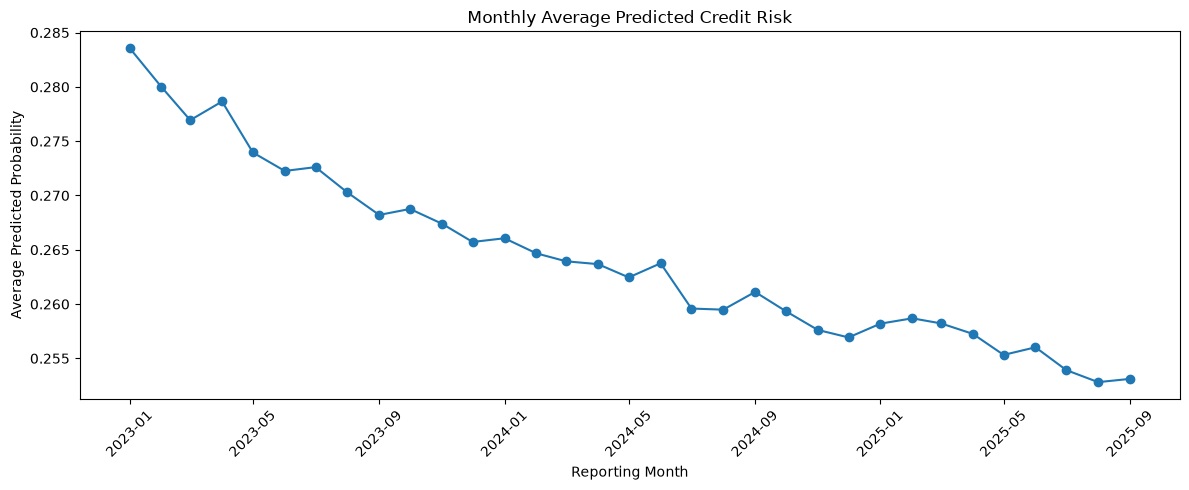

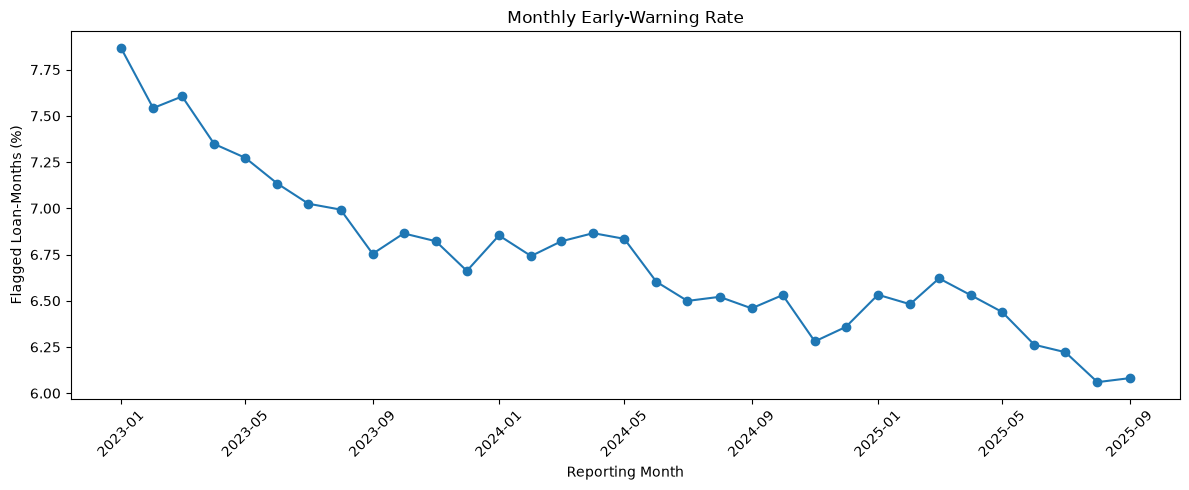

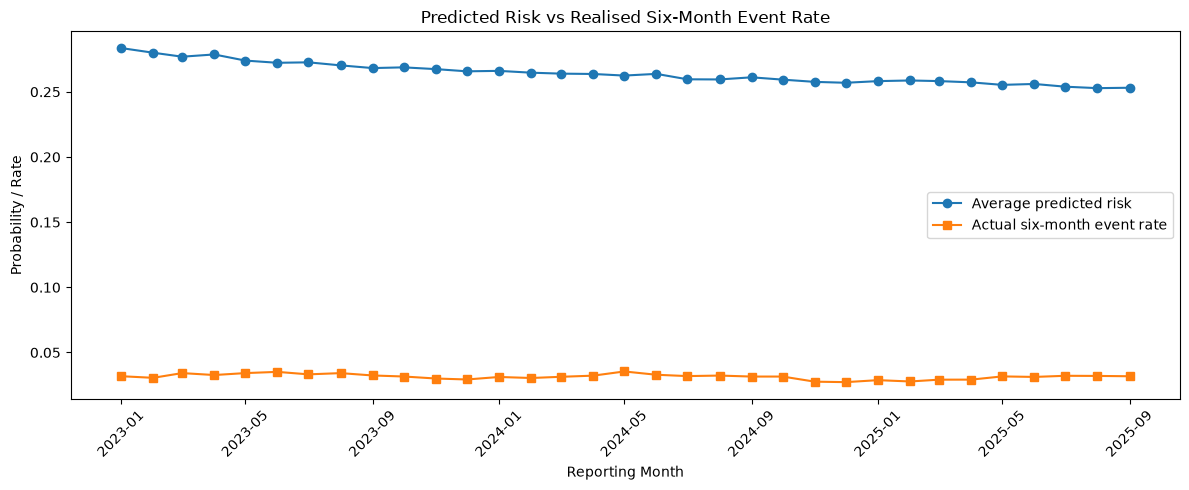

In [10]:
# ============================================================
# SECTION 8B: MONTHLY RISK EVOLUTION CHARTS
# ============================================================

import matplotlib.pyplot as plt

# Convert reporting month
monthly_risk_summary["reporting_month"] = pd.to_datetime(
    monthly_risk_summary["reporting_month"]
)

# 1. Average predicted risk
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_risk_summary["reporting_month"],
    monthly_risk_summary["average_predicted_risk"],
    marker="o"
)

plt.title("Monthly Average Predicted Credit Risk")
plt.xlabel("Reporting Month")
plt.ylabel("Average Predicted Probability")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    DYNAMIC_FIGURES_DIR / "monthly_average_predicted_risk.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 2. Monthly warning rate
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_risk_summary["reporting_month"],
    monthly_risk_summary["warning_rate"] * 100,
    marker="o"
)

plt.title("Monthly Early-Warning Rate")
plt.xlabel("Reporting Month")
plt.ylabel("Flagged Loan-Months (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    DYNAMIC_FIGURES_DIR / "monthly_warning_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 3. Predicted risk versus realised event rate
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_risk_summary["reporting_month"],
    monthly_risk_summary["average_predicted_risk"],
    marker="o",
    label="Average predicted risk"
)

plt.plot(
    monthly_risk_summary["reporting_month"],
    monthly_risk_summary["actual_six_month_event_rate"],
    marker="s",
    label="Actual six-month event rate"
)

plt.title("Predicted Risk vs Realised Six-Month Event Rate")
plt.xlabel("Reporting Month")
plt.ylabel("Probability / Rate")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    DYNAMIC_FIGURES_DIR / "predicted_vs_realised_monthly_risk.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 9. Borrower-Level Risk Trajectory Summary

The monthly prediction records are aggregated at the borrower level to create a longitudinal risk profile.

The borrower-level summary includes average, maximum and latest predicted risk, warning frequency, observation coverage and recent risk movement.

The latest warning state is classified separately from the direction of recent risk movement. This distinction prevents a rising probability from being automatically interpreted as a threshold breach.


In [11]:
# ============================================================
# SECTION 9A: BORROWER-LEVEL RISK AGGREGATION
# ============================================================

BORROWER_SUMMARY_FILE = (
    DYNAMIC_OUTPUT_DIR /
    "borrower_risk_summary.parquet"
)

con = duckdb.connect()

borrower_summary_query = f"""
COPY (

    WITH aggregate_metrics AS (

        SELECT
            loan_id,

            COUNT(*) AS observed_months,

            AVG(predicted_probability)
                AS average_predicted_risk,

            MAX(predicted_probability)
                AS maximum_predicted_risk,

            MIN(predicted_probability)
                AS minimum_predicted_risk,

            SUM(warning_flag_058)
                AS flagged_months,

            AVG(warning_flag_058)
                AS flagged_month_proportion,

            MIN(reporting_date)
                AS first_reporting_date,

            MAX(reporting_date)
                AS last_reporting_date,

            SUM(target_6m)
                AS observed_six_month_events

        FROM read_parquet(
            '{TRAJECTORY_FILE.as_posix()}'
        )

        GROUP BY loan_id

    ),

    latest_record AS (

        SELECT
            loan_id,
            reporting_date AS latest_reporting_date,
            predicted_probability AS latest_predicted_risk,
            warning_flag_058 AS latest_warning_flag,
            previous_month_warning,
            has_valid_previous_month,
            risk_change_1m,
            risk_change_3m,
            has_valid_three_month_history

        FROM read_parquet(
            '{TRAJECTORY_FILE.as_posix()}'
        )

        QUALIFY ROW_NUMBER() OVER (
            PARTITION BY loan_id
            ORDER BY reporting_date DESC
        ) = 1

    )

    SELECT
        a.*,
        l.latest_reporting_date,
        l.latest_predicted_risk,
        l.latest_warning_flag,
        l.previous_month_warning,
        l.has_valid_previous_month,
        l.risk_change_1m,
        l.risk_change_3m,
        l.has_valid_three_month_history

    FROM aggregate_metrics a

    INNER JOIN latest_record l
        ON a.loan_id = l.loan_id

) TO '{BORROWER_SUMMARY_FILE.as_posix()}'
(FORMAT PARQUET, COMPRESSION ZSTD)
"""

con.execute(borrower_summary_query)

con.close()

print("BORROWER SUMMARY CREATED")
print(BORROWER_SUMMARY_FILE)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

BORROWER SUMMARY CREATED
C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\data\processed\dynamic_risk\borrower_risk_summary.parquet


In [12]:
# ============================================================
# SECTION 9B: LATEST BORROWER WARNING CLASSIFICATION
# ============================================================

con = duckdb.connect()

borrower_classification = con.execute(
    f"""
    SELECT
        loan_id,
        latest_reporting_date,
        latest_predicted_risk,
        latest_warning_flag,
        previous_month_warning,
        has_valid_previous_month,
        risk_change_3m,

        CASE

            WHEN latest_warning_flag = 1
             AND has_valid_previous_month = 1
             AND previous_month_warning = 1
            THEN 'consecutive_warning_2plus'

            WHEN latest_warning_flag = 1
             AND has_valid_previous_month = 1
             AND previous_month_warning = 0
            THEN 'newly_flagged'

            WHEN latest_warning_flag = 1
             AND has_valid_previous_month = 0
            THEN 'flagged_insufficient_history'

            WHEN latest_warning_flag = 0
             AND has_valid_previous_month = 1
             AND previous_month_warning = 1
            THEN 'de_escalated'

            ELSE 'below_threshold'

        END AS latest_warning_state,

        CASE

            WHEN risk_change_3m > 0
            THEN 'increasing'

            WHEN risk_change_3m < 0
            THEN 'decreasing'

            WHEN risk_change_3m = 0
            THEN 'unchanged'

            ELSE 'insufficient_history'

        END AS three_month_risk_direction

    FROM read_parquet(
        '{BORROWER_SUMMARY_FILE.as_posix()}'
    )
    """
).fetchdf()

con.close()

borrower_classification.to_csv(
    DYNAMIC_OUTPUT_DIR /
    "borrower_latest_warning_classification.csv",
    index=False
)

print("LATEST WARNING STATE DISTRIBUTION")

display(
    borrower_classification[
        "latest_warning_state"
    ].value_counts().to_frame("borrowers")
)

print("\nTHREE-MONTH RISK DIRECTION")

display(
    borrower_classification[
        "three_month_risk_direction"
    ].value_counts().to_frame("borrowers")
)

print("\nBORROWER CLASSIFICATION COMPLETED")

LATEST WARNING STATE DISTRIBUTION


,borrowers
latest_warning_state,
below_threshold,126739
consecutive_warning_2plus,8986
flagged_insufficient_history,2201
de_escalated,587
newly_flagged,207



THREE-MONTH RISK DIRECTION


,borrowers
three_month_risk_direction,
unchanged,71200
decreasing,41955
increasing,18722
insufficient_history,6843



BORROWER CLASSIFICATION COMPLETED



## 10. Predicted Risk Calibration Assessment

This section evaluates the agreement between model-predicted probabilities and observed six-month delinquency frequencies on the untouched out-of-time test dataset.

The analysis includes:

- Mean predicted probability.
- Observed event rate.
- Brier score.
- Constant-prevalence benchmark Brier score.
- Brier Skill Score.
- Decile-based calibration analysis.

This assessment is necessary before interpreting raw model probabilities as calibrated probabilities of delinquency or using them as PD inputs in expected-loss calculations.


In [13]:

# ============================================================
# SECTION 10A: TEST CALIBRATION AUDIT
# ============================================================

con = duckdb.connect()

calibration_metrics = con.execute(
    f"""
    WITH base AS (

        SELECT
            predicted_probability AS p,
            target_6m AS y

        FROM read_parquet(
            '{TEST_RISK_FILE.as_posix()}'
        )

    ),

    prevalence AS (

        SELECT AVG(y) AS event_rate
        FROM base

    ),

    metrics AS (

        SELECT
            COUNT(*) AS observations,
            AVG(p) AS mean_predicted_probability,
            AVG(y) AS observed_event_rate,

            AVG(
                POWER(p - y, 2)
            ) AS model_brier_score,

            AVG(
                POWER(y - event_rate, 2)
            ) AS benchmark_brier_score

        FROM base
        CROSS JOIN prevalence
    )

    SELECT
        *,
        1.0 -
        model_brier_score /
        NULLIF(benchmark_brier_score, 0)
        AS brier_skill_score

    FROM metrics
    """
).fetchdf()

con.close()

display(calibration_metrics.T)

print("\nCALIBRATION METRICS GENERATED")


,0
observations,2.483739e+06
mean_predicted_probability,2.592882e-01
observed_event_rate,3.094568e-02
model_brier_score,9.434974e-02
benchmark_brier_score,2.998805e-02
brier_skill_score,-2.146245e+00



CALIBRATION METRICS GENERATED


In [14]:

# ============================================================
# SECTION 10B: DECILE CALIBRATION TABLE
# ============================================================

con = duckdb.connect()

calibration_deciles = con.execute(
    f"""
    WITH ranked AS (

        SELECT
            predicted_probability,
            target_6m,

            NTILE(10) OVER (
                ORDER BY predicted_probability
            ) AS risk_decile

        FROM read_parquet(
            '{TEST_RISK_FILE.as_posix()}'
        )

    )

    SELECT
        risk_decile,
        COUNT(*) AS observations,
        AVG(predicted_probability)
            AS mean_predicted_probability,
        AVG(target_6m)
            AS observed_event_rate,
        MIN(predicted_probability)
            AS minimum_score,
        MAX(predicted_probability)
            AS maximum_score

    FROM ranked

    GROUP BY risk_decile
    ORDER BY risk_decile
    """
).fetchdf()

con.close()

display(calibration_deciles.round(6))

calibration_deciles.to_csv(
    DYNAMIC_OUTPUT_DIR /
    "test_calibration_deciles.csv",
    index=False
)

print("\nDECILE CALIBRATION TABLE SAVED")


,risk_decile,observations,mean_predicted_probability,observed_event_rate,minimum_score,maximum_score
0,1,248374,0.054921,0.004876,0.003022,0.079581
1,2,248374,0.098404,0.006237,0.079581,0.116236
2,3,248374,0.133291,0.008519,0.116236,0.150078
3,4,248374,0.166566,0.009063,0.150078,0.183278
4,5,248374,0.200919,0.012336,0.183278,0.218949
5,6,248374,0.238057,0.013480,0.218949,0.258028
6,7,248374,0.279921,0.017123,0.258028,0.303527
7,8,248374,0.332327,0.021806,0.303528,0.365146
8,9,248374,0.413257,0.030088,0.365146,0.479700
9,10,248373,0.675220,0.185930,0.479703,0.975343



DECILE CALIBRATION TABLE SAVED


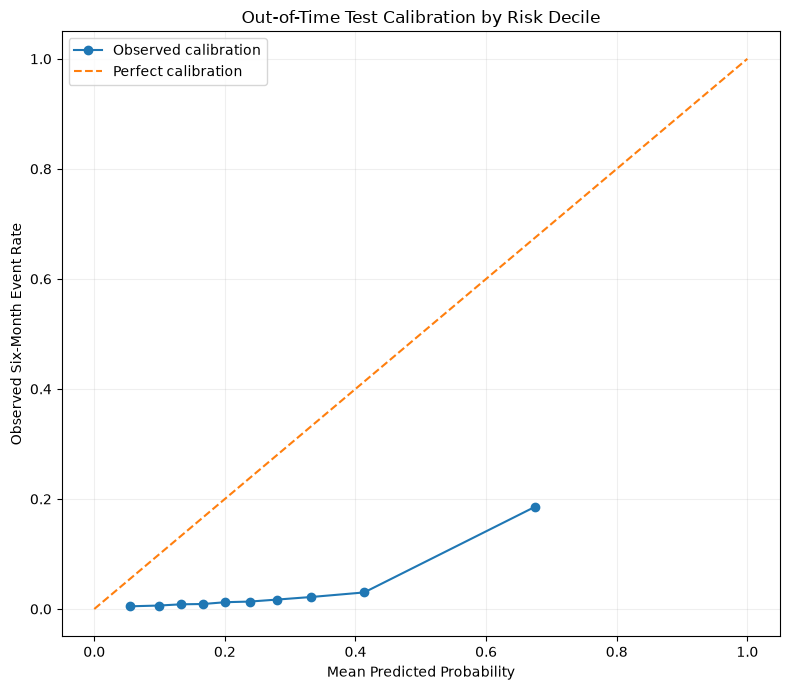

In [15]:

# ============================================================
# SECTION 10C: CALIBRATION CURVE
# ============================================================

plt.figure(figsize=(8, 7))

plt.plot(
    calibration_deciles["mean_predicted_probability"],
    calibration_deciles["observed_event_rate"],
    marker="o",
    label="Observed calibration"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Six-Month Event Rate")
plt.title("Out-of-Time Test Calibration by Risk Decile")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    DYNAMIC_FIGURES_DIR /
    "test_calibration_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [16]:
# ============================================================
# STORAGE AUDIT - MTP PROJECT
# ============================================================

def get_size_mb(path):
    path = Path(path)

    if not path.exists():
        return 0

    if path.is_file():
        return path.stat().st_size / (1024 ** 2)

    return sum(
        f.stat().st_size
        for f in path.rglob("*")
        if f.is_file()
    ) / (1024 ** 2)


folders = {
    "Models": MODELS_DIR,
    "Transformed datasets": TRANSFORMED_DIR,
    "Dynamic risk": DYNAMIC_OUTPUT_DIR,
    "Figures": PROJECT_DIR / "figures"
}

print("MTP STORAGE INVENTORY\n")

total_mb = 0

for name, path in folders.items():
    size = get_size_mb(path)
    total_mb += size

    print(
        f"{name:25} : {size:,.2f} MB"
    )

print("\nTOTAL INVENTORIED SIZE:", round(total_mb, 2), "MB")

print("\nIMPORTANT FILES")

important_files = [
    HGB_MODEL_FILE,
    VALIDATION_RISK_FILE,
    TEST_RISK_FILE,
    TRAJECTORY_FILE,
    BORROWER_SUMMARY_FILE
]

for file in important_files:
    if file.exists():
        print(
            file.name,
            round(file.stat().st_size / (1024 ** 2), 2),
            "MB"
        )
    else:
        print(file.name, "NOT FOUND")

MTP STORAGE INVENTORY

Models                    : 21.45 MB
Transformed datasets      : 530.61 MB
Dynamic risk              : 83.16 MB
Figures                   : 2.57 MB

TOTAL INVENTORIED SIZE: 637.79 MB

IMPORTANT FILES
hist_gradient_boosting_baseline.joblib 0.74 MB
validation_dynamic_risk.parquet 8.19 MB
test_dynamic_risk.parquet 8.71 MB
borrower_monthly_risk_trajectories.parquet 48.63 MB
borrower_risk_summary.parquet 5.74 MB



## 11. Probability Recalibration

The previous out-of-time assessment identified substantial overprediction in the raw HGB scores.

A sigmoid-based logistic recalibration mapping is fitted using the complete 2023 validation predictions and observed outcomes.

The mapping is fitted on the logit of the raw HGB probability. The original HGB model is not retrained.

The fitted coefficients are applied to the 2024–September 2025 test predictions using DuckDB SQL. Test outcomes are used only for final evaluation, never for fitting or selecting the calibration mapping.


In [17]:
# ============================================================
# SECTION 11A: FIT SIGMOID RECALIBRATION ON VALIDATION ONLY
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
from pathlib import Path
import pandas as pd
import numpy as np
import json
import duckdb
import gc

CALIBRATION_DIR = DYNAMIC_OUTPUT_DIR / "calibration"
CALIBRATION_DIR.mkdir(parents=True, exist_ok=True)

CALIBRATOR_FILE = (
    CALIBRATION_DIR / "sigmoid_calibration_parameters.json"
)

if CALIBRATOR_FILE.exists():
    raise FileExistsError(
        "Calibration parameter file already exists. "
        "Inspect it before fitting another calibrator."
    )

# Read only two columns: raw score and actual outcome
con = duckdb.connect()

validation_calibration = con.execute(
    f"""
    SELECT
        predicted_probability,
        target_6m
    FROM read_parquet(
        '{VALIDATION_RISK_FILE.as_posix()}'
    )
    """
).fetchdf()

con.close()

raw_val = validation_calibration[
    "predicted_probability"
].to_numpy(dtype=np.float64)

y_val = validation_calibration[
    "target_6m"
].to_numpy(dtype=np.int8)

# Logit transformation with numerical clipping
eps = 1e-6

val_logits = np.log(
    np.clip(raw_val, eps, 1-eps) /
    (1 - np.clip(raw_val, eps, 1-eps))
).reshape(-1, 1)

# Fit logistic recalibration on validation only
calibrator = LogisticRegression(
    C=1e6,
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

calibrator.fit(val_logits, y_val)

calibration_slope = float(calibrator.coef_[0, 0])
calibration_intercept = float(calibrator.intercept_[0])

# Validation assessment
val_calibrated = calibrator.predict_proba(
    val_logits
)[:, 1]

print("VALIDATION OBSERVATIONS:", len(y_val))
print("VALIDATION EVENT RATE:", y_val.mean())
print("CALIBRATION SLOPE:", calibration_slope)
print("CALIBRATION INTERCEPT:", calibration_intercept)

print(
    "RAW VALIDATION BRIER:",
    brier_score_loss(y_val, raw_val)
)

print(
    "CALIBRATED VALIDATION BRIER:",
    brier_score_loss(y_val, val_calibrated)
)

# Save compact calibration parameters
calibration_parameters = {
    "method": "sigmoid_logistic_recalibration",
    "input_transform": "logit_raw_hgb_probability",
    "slope": calibration_slope,
    "intercept": calibration_intercept,
    "epsilon": eps,
    "fitting_period": "2023-01 to 2023-12",
    "fitting_observations": int(len(y_val)),
    "fitting_events": int(y_val.sum()),
    "test_used_for_fitting": False,
    "base_model": "HistGradientBoostingClassifier",
    "base_model_changed": False,
    "original_raw_warning_threshold": 0.58
}

with open(CALIBRATOR_FILE, "w", encoding="utf-8") as f:
    json.dump(calibration_parameters, f, indent=2)

print("\nCALIBRATION PARAMETERS SAVED:")
print(CALIBRATOR_FILE)

del validation_calibration, val_logits, val_calibrated
gc.collect()

VALIDATION OBSERVATIONS: 1569879
VALIDATION EVENT RATE: 0.03245600457105293
CALIBRATION SLOPE: 1.1240113501258775
CALIBRATION INTERCEPT: -2.82259655926534
RAW VALIDATION BRIER: 0.10384450448614656
CALIBRATED VALIDATION BRIER: 0.027124674033119005

CALIBRATION PARAMETERS SAVED:
C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\data\processed\dynamic_risk\calibration\sigmoid_calibration_parameters.json


13706


## 12. Out-of-Time Calibration Evaluation

The fitted validation-only calibration mapping is applied directly to raw test predictions.

The evaluation compares raw and recalibrated probabilities using:

- Mean predicted probability.
- Observed event rate.
- Brier score.
- Constant-prevalence benchmark Brier score.
- Brier Skill Score.

The test dataset remains unchanged. Calibrated values are calculated in SQL and only aggregate results are retained.


In [18]:
# ============================================================
# SECTION 12A: OUT-OF-TIME CALIBRATION EVALUATION
# ============================================================

with open(CALIBRATOR_FILE, "r", encoding="utf-8") as f:
    calibration_parameters = json.load(f)

a = calibration_parameters["slope"]
b = calibration_parameters["intercept"]
eps = calibration_parameters["epsilon"]

TEST_CALIBRATION_METRICS = (
    CALIBRATION_DIR / "test_calibration_metrics.csv"
)

TEST_CALIBRATION_DECILES = (
    CALIBRATION_DIR / "test_calibration_deciles.csv"
)

# Calculate calibrated probability inside DuckDB.
# No calibrated row-level dataset is written to disk.

probability_expression = f"""
1.0 / (
    1.0 + EXP(
        -(
            ({a:.17g}) *
            LN(
                GREATEST(
                    LEAST(predicted_probability, {1-eps:.17g}),
                    {eps:.17g}
                )
                /
                (
                    1.0 -
                    GREATEST(
                        LEAST(predicted_probability, {1-eps:.17g}),
                        {eps:.17g}
                    )
                )
            )
            + ({b:.17g})
        )
    )
)
"""

con = duckdb.connect()

metrics_query = f"""
WITH scored AS (

    SELECT
        target_6m AS y,
        predicted_probability AS raw_probability,
        {probability_expression}
            AS calibrated_probability

    FROM read_parquet(
        '{TEST_RISK_FILE.as_posix()}'
    )

),

prevalence AS (

    SELECT AVG(y) AS event_rate
    FROM scored

),

metric_values AS (

    SELECT
        COUNT(*) AS observations,
        AVG(y) AS observed_event_rate,
        AVG(raw_probability) AS raw_mean_probability,
        AVG(calibrated_probability)
            AS calibrated_mean_probability,

        AVG(POWER(raw_probability - y, 2))
            AS raw_brier_score,

        AVG(POWER(calibrated_probability - y, 2))
            AS calibrated_brier_score

    FROM scored

)

SELECT
    *,
    event_rate * (1.0 - event_rate)
        AS benchmark_brier_score,

    1.0 -
    raw_brier_score /
    NULLIF(event_rate * (1.0 - event_rate), 0)
        AS raw_brier_skill_score,

    1.0 -
    calibrated_brier_score /
    NULLIF(event_rate * (1.0 - event_rate), 0)
        AS calibrated_brier_skill_score

FROM metric_values
CROSS JOIN prevalence
"""

test_calibration_metrics = con.execute(
    metrics_query
).fetchdf()

display(test_calibration_metrics.T)

test_calibration_metrics.to_csv(
    TEST_CALIBRATION_METRICS,
    index=False
)

print("\nTEST CALIBRATION METRICS SAVED")

,0
observations,2.483739e+06
observed_event_rate,3.094568e-02
raw_mean_probability,2.592882e-01
calibrated_mean_probability,3.044704e-02
raw_brier_score,9.434974e-02
calibrated_brier_score,2.513269e-02
event_rate,3.094568e-02
benchmark_brier_score,2.998805e-02
raw_brier_skill_score,-2.146245e+00
calibrated_brier_skill_score,1.619098e-01



TEST CALIBRATION METRICS SAVED


In [19]:
# ============================================================
# SECTION 12B: CALIBRATED TEST DECILE ANALYSIS
# ============================================================

decile_query = f"""
WITH scored AS (

    SELECT
        target_6m,
        predicted_probability AS raw_probability,
        {probability_expression}
            AS calibrated_probability

    FROM read_parquet(
        '{TEST_RISK_FILE.as_posix()}'
    )

),

ranked AS (

    SELECT
        *,
        NTILE(10) OVER (
            ORDER BY calibrated_probability
        ) AS calibrated_decile

    FROM scored

)

SELECT
    calibrated_decile,
    COUNT(*) AS observations,

    AVG(raw_probability)
        AS mean_raw_probability,

    AVG(calibrated_probability)
        AS mean_calibrated_probability,

    AVG(target_6m)
        AS observed_event_rate,

    MIN(calibrated_probability)
        AS minimum_calibrated_probability,

    MAX(calibrated_probability)
        AS maximum_calibrated_probability

FROM ranked

GROUP BY calibrated_decile
ORDER BY calibrated_decile
"""

con = duckdb.connect()

calibrated_deciles = con.execute(
    decile_query
).fetchdf()

con.close()

display(calibrated_deciles.round(6))

calibrated_deciles.to_csv(
    TEST_CALIBRATION_DECILES,
    index=False
)

print("\nCALIBRATED TEST DECILES SAVED")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,calibrated_decile,observations,mean_raw_probability,mean_calibrated_probability,observed_event_rate,minimum_calibrated_probability,maximum_calibrated_probability
0,1,248374,0.054921,0.002455,0.004876,0.000088,0.003780
1,2,248374,0.098404,0.004918,0.006237,0.003780,0.006043
2,3,248374,0.133291,0.007207,0.008519,0.006043,0.008396
3,4,248374,0.166566,0.009648,0.009063,0.008396,0.010963
4,5,248374,0.200919,0.012454,0.012336,0.010963,0.014034
5,6,248374,0.238057,0.015844,0.013480,0.014034,0.017813
6,7,248374,0.279921,0.020172,0.017123,0.017813,0.022840
7,8,248374,0.332327,0.026489,0.021806,0.022840,0.030940
8,9,248374,0.413257,0.038869,0.030088,0.030940,0.051470
9,10,248373,0.675220,0.166415,0.185930,0.051471,0.787716



CALIBRATED TEST DECILES SAVED


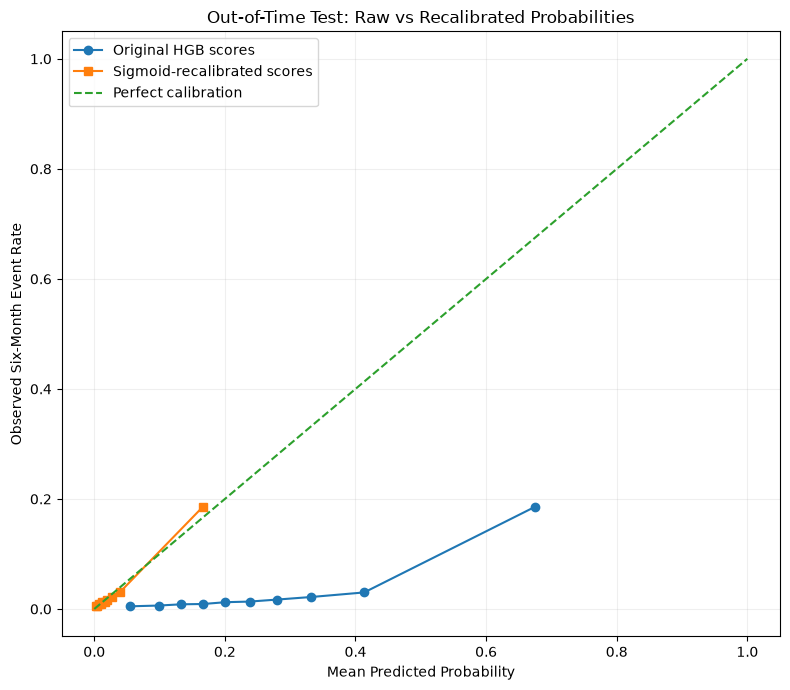

In [20]:
# ============================================================
# SECTION 12C: CALIBRATION COMPARISON CHART
# ============================================================

plt.figure(figsize=(8, 7))

plt.plot(
    calibration_deciles["mean_predicted_probability"],
    calibration_deciles["observed_event_rate"],
    marker="o",
    label="Original HGB scores"
)

plt.plot(
    calibrated_deciles["mean_calibrated_probability"],
    calibrated_deciles["observed_event_rate"],
    marker="s",
    label="Sigmoid-recalibrated scores"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Six-Month Event Rate")

plt.title(
    "Out-of-Time Test: Raw vs Recalibrated Probabilities"
)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    DYNAMIC_FIGURES_DIR /
    "raw_vs_calibrated_test_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 13. Borrower-Level Early-Warning System

The Early-Warning System (EWS) translates monthly model predictions into borrower-level warning states.

The system uses the validation-selected raw HGB score threshold of 0.58 and the availability of consecutive monthly observations.

Borrowers are classified into:
- Persistent warning
- Newly flagged
- Warning with insufficient history
- De-escalated
- No active warning

The system additionally identifies recent risk direction using the three-month raw score change.

A separate sigmoid-calibrated probability is retained for probability-based risk interpretation.

The EWS categories are monitoring classifications, not confirmed defaults or causal indicators.


In [21]:
# ============================================================
# SECTION 13A: BUILD BORROWER-LEVEL EWS REGISTER
# ============================================================

import json
import duckdb
from pathlib import Path

EWS_REGISTER_FILE = (
    DYNAMIC_OUTPUT_DIR /
    "borrower_ews_register.parquet"
)

EWS_SUMMARY_FILE = (
    DYNAMIC_OUTPUT_DIR /
    "borrower_ews_summary.csv"
)

with open(CALIBRATOR_FILE, "r", encoding="utf-8") as f:
    calibration_parameters = json.load(f)

a = calibration_parameters["slope"]
b = calibration_parameters["intercept"]
eps = calibration_parameters["epsilon"]

if EWS_REGISTER_FILE.exists():
    raise FileExistsError(
        "EWS register already exists. Inspect it before overwriting."
    )

raw_score = "latest_predicted_risk"

calibrated_score = f"""
1.0 / (
    1.0 + EXP(
        -(
            ({a:.17g}) *
            LN(
                GREATEST(
                    LEAST({raw_score}, {1-eps:.17g}),
                    {eps:.17g}
                )
                /
                (
                    1.0 -
                    GREATEST(
                        LEAST({raw_score}, {1-eps:.17g}),
                        {eps:.17g}
                    )
                )
            )
            + ({b:.17g})
        )
    )
)
"""

con = duckdb.connect()

ews_query = f"""
COPY (

    WITH base AS (

        SELECT
            loan_id,
            first_reporting_date,
            last_reporting_date,
            observed_months,
            average_predicted_risk,
            maximum_predicted_risk,
            flagged_months,
            flagged_month_proportion,
            latest_reporting_date,
            latest_predicted_risk,
            latest_warning_flag,
            previous_month_warning,
            has_valid_previous_month,
            risk_change_1m,
            risk_change_3m,
            has_valid_three_month_history,

            {calibrated_score}
                AS latest_calibrated_probability

        FROM read_parquet(
            '{BORROWER_SUMMARY_FILE.as_posix()}'
        )

    ),

    classified AS (

        SELECT
            *,

            CASE

                WHEN latest_warning_flag = 1
                 AND has_valid_previous_month = 1
                 AND previous_month_warning = 1
                THEN 'PERSISTENT_WARNING'

                WHEN latest_warning_flag = 1
                 AND has_valid_previous_month = 1
                 AND previous_month_warning = 0
                THEN 'NEWLY_FLAGGED'

                WHEN latest_warning_flag = 1
                 AND has_valid_previous_month = 0
                THEN 'WARNING_INSUFFICIENT_HISTORY'

                WHEN latest_warning_flag = 0
                 AND has_valid_previous_month = 1
                 AND previous_month_warning = 1
                THEN 'DE_ESCALATED'

                ELSE 'NO_ACTIVE_WARNING'

            END AS ews_status,

            CASE

                WHEN has_valid_three_month_history = 0
                THEN 'INSUFFICIENT_HISTORY'

                WHEN risk_change_3m > 0
                THEN 'INCREASING'

                WHEN risk_change_3m < 0
                THEN 'DECREASING'

                ELSE 'UNCHANGED'

            END AS recent_risk_direction

        FROM base

    )

    SELECT
        *,

        CASE

            WHEN ews_status = 'PERSISTENT_WARNING'
             AND recent_risk_direction = 'INCREASING'
            THEN 'HIGH_REVIEW'

            WHEN ews_status IN (
                'PERSISTENT_WARNING',
                'NEWLY_FLAGGED',
                'WARNING_INSUFFICIENT_HISTORY'
            )
            THEN 'STANDARD_REVIEW'

            WHEN ews_status IN (
                'DE_ESCALATED'
            )
            THEN 'MONITOR'

            WHEN ews_status = 'NO_ACTIVE_WARNING'
             AND recent_risk_direction = 'INCREASING'
            THEN 'WATCH'

            ELSE 'ROUTINE_MONITORING'

        END AS review_category

    FROM classified

) TO '{EWS_REGISTER_FILE.as_posix()}'
(FORMAT PARQUET, COMPRESSION ZSTD)
"""

con.execute(ews_query)

print("EWS REGISTER CREATED")
print(EWS_REGISTER_FILE)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

EWS REGISTER CREATED
C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\data\processed\dynamic_risk\borrower_ews_register.parquet


In [22]:
# ============================================================
# SECTION 13B: EWS REGISTER AUDIT
# ============================================================

con = duckdb.connect()

ews_summary = con.execute(
    f"""
    SELECT
        COUNT(*) AS unique_borrowers,

        SUM(latest_warning_flag)
            AS latest_flagged_borrowers,

        AVG(latest_calibrated_probability)
            AS average_calibrated_probability,

        SUM(
            CASE WHEN ews_status = 'PERSISTENT_WARNING'
            THEN 1 ELSE 0 END
        ) AS persistent_warning,

        SUM(
            CASE WHEN ews_status = 'NEWLY_FLAGGED'
            THEN 1 ELSE 0 END
        ) AS newly_flagged,

        SUM(
            CASE WHEN ews_status = 'WARNING_INSUFFICIENT_HISTORY'
            THEN 1 ELSE 0 END
        ) AS insufficient_history_warning,

        SUM(
            CASE WHEN ews_status = 'DE_ESCALATED'
            THEN 1 ELSE 0 END
        ) AS de_escalated,

        SUM(
            CASE WHEN ews_status = 'NO_ACTIVE_WARNING'
            THEN 1 ELSE 0 END
        ) AS no_active_warning

    FROM read_parquet(
        '{EWS_REGISTER_FILE.as_posix()}'
    )
    """
).fetchdf()

display(ews_summary.T)

ews_summary.to_csv(
    EWS_SUMMARY_FILE,
    index=False
)

# Check category reconciliation
category_total = int(
    ews_summary[
        [
            "persistent_warning",
            "newly_flagged",
            "insufficient_history_warning",
            "de_escalated",
            "no_active_warning"
        ]
    ].sum(axis=1).iloc[0]
)

borrower_total = int(
    ews_summary["unique_borrowers"].iloc[0]
)

print("\nCATEGORY RECONCILIATION:",
      category_total == borrower_total)

print("BORROWER COUNT:", borrower_total)
print("CATEGORY TOTAL:", category_total)

assert category_total == borrower_total
assert borrower_total == 138720

con.close()

print("\nEWS REGISTER AUDIT: PASS")

,0
unique_borrowers,138720.000000
latest_flagged_borrowers,11394.000000
average_calibrated_probability,0.036109
persistent_warning,8986.000000
newly_flagged,207.000000
insufficient_history_warning,2201.000000
de_escalated,587.000000
no_active_warning,126739.000000



CATEGORY RECONCILIATION: True
BORROWER COUNT: 138720
CATEGORY TOTAL: 138720

EWS REGISTER AUDIT: PASS


In [23]:
# ============================================================
# SECTION 13C: EWS REVIEW CATEGORY DISTRIBUTION
# ============================================================

con = duckdb.connect()

review_distribution = con.execute(
    f"""
    SELECT
        review_category,
        COUNT(*) AS borrowers,

        AVG(latest_calibrated_probability)
            AS average_calibrated_probability,

        AVG(latest_predicted_risk)
            AS average_raw_hgb_score

    FROM read_parquet(
        '{EWS_REGISTER_FILE.as_posix()}'
    )

    GROUP BY review_category
    ORDER BY borrowers DESC
    """
).fetchdf()

con.close()

display(review_distribution.round(5))

review_distribution.to_csv(
    DYNAMIC_OUTPUT_DIR /
    "ews_review_category_distribution.csv",
    index=False
)

print("\nEWS REVIEW DISTRIBUTION SAVED")

,review_category,borrowers,average_calibrated_probability,average_raw_hgb_score
0,ROUTINE_MONITORING,108770,0.01635,0.21777
1,WATCH,17969,0.01767,0.22926
2,STANDARD_REVIEW,10771,0.25767,0.78125
3,HIGH_REVIEW,623,0.16654,0.71842
4,MONITOR,587,0.05737,0.49459



EWS REVIEW DISTRIBUTION SAVED



## 14. Portfolio-Level Risk and Exposure Analysis

This section constructs a common-date portfolio snapshot using out-of-time test predictions.

The snapshot date is September 2025, the final reporting month in the test period.

Model scores and warning states are linked with contemporaneous outstanding unpaid principal balance (UPB) and selected loan characteristics.

Portfolio analysis will examine:
- Outstanding exposure.
- Warning-category exposure.
- Exposure concentration.
- Geographic and loan-characteristic risk distribution.

The analysis uses loan-level outstanding balances as exposure proxies. It does not assume that UPB is equivalent to accounting exposure at default (EAD).


In [24]:
# ============================================================
# SECTION 14A: VERIFY PORTFOLIO SOURCE DATA
# ============================================================

FINAL_FEATURE_FILE = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "feature_engineering"
    / "fannie_2018Q1_final_modelling_features.parquet"
)

PORTFOLIO_DIR = DYNAMIC_OUTPUT_DIR / "portfolio"
PORTFOLIO_DIR.mkdir(parents=True, exist_ok=True)

print("FINAL FEATURE DATA EXISTS:", FINAL_FEATURE_FILE.exists())
print("TEST RISK DATA EXISTS:", TEST_RISK_FILE.exists())
print("TRAJECTORY DATA EXISTS:", TRAJECTORY_FILE.exists())

con = duckdb.connect()

for label, file in [
    ("FINAL FEATURE DATA", FINAL_FEATURE_FILE),
    ("TEST RISK DATA", TEST_RISK_FILE),
    ("TRAJECTORY DATA", TRAJECTORY_FILE)
]:
    print(f"\n{label} SCHEMA")

    schema = con.execute(
        f"""
        DESCRIBE
        SELECT *
        FROM read_parquet('{file.as_posix()}')
        """
    ).fetchdf()

    print(
        schema[
            schema["column_name"].isin([
                "loan_id",
                "reporting_date",
                "current_actual_upb",
                "original_upb",
                "property_state",
                "loan_purpose",
                "channel",
                "original_ltv",
                "target_6m",
                "predicted_probability",
                "warning_flag_058",
                "warning_transition",
                "risk_change_3m"
            ])
        ].to_string(index=False)
    )

con.close()

print("\nSOURCE SCHEMA INSPECTION COMPLETED")

FINAL FEATURE DATA EXISTS: True
TEST RISK DATA EXISTS: True
TRAJECTORY DATA EXISTS: True

FINAL FEATURE DATA SCHEMA
       column_name column_type null  key default extra
           loan_id      BIGINT  YES None    None  None
    reporting_date   TIMESTAMP  YES None    None  None
         target_6m     INTEGER  YES None    None  None
           channel     VARCHAR  YES None    None  None
      original_upb      DOUBLE  YES None    None  None
current_actual_upb      DOUBLE  YES None    None  None
      original_ltv      BIGINT  YES None    None  None
      loan_purpose     VARCHAR  YES None    None  None
    property_state     VARCHAR  YES None    None  None

TEST RISK DATA SCHEMA
          column_name column_type null  key default extra
              loan_id      BIGINT  YES None    None  None
       reporting_date   TIMESTAMP  YES None    None  None
            target_6m     TINYINT  YES None    None  None
predicted_probability      DOUBLE  YES None    None  None
     warning_flag_058


## 14B. Common-Date Portfolio Snapshot Validation

A common reporting date of 1 September 2025 is selected for portfolio-level analysis.

The test prediction dataset, trajectory dataset and final modelling feature dataset are joined using loan_id and reporting_date.

The audit verifies:
- Source population reconciliation.
- Unique loan-month records.
- Matching records across the three datasets.
- Availability and validity of outstanding UPB.

Only matched observations with valid outstanding UPB will contribute to exposure calculations.


In [26]:
# ============================================================
# SECTION 14B: COMMON-DATE PORTFOLIO SNAPSHOT AUDIT
# ============================================================

SNAPSHOT_DATE = "2025-09-01"

con = duckdb.connect()

snapshot_audit = con.execute(
    f"""
    WITH test_data AS (

        SELECT *
        FROM read_parquet(
            '{TEST_RISK_FILE.as_posix()}'
        )
        WHERE reporting_date = DATE '{SNAPSHOT_DATE}'

    ),

    trajectory_data AS (

        SELECT *
        FROM read_parquet(
            '{TRAJECTORY_FILE.as_posix()}'
        )
        WHERE reporting_date = DATE '{SNAPSHOT_DATE}'

    ),

    feature_data AS (

        SELECT
            loan_id,
            reporting_date,
            current_actual_upb,
            property_state,
            loan_purpose,
            channel,
            original_ltv
        FROM read_parquet(
            '{FINAL_FEATURE_FILE.as_posix()}'
        )
        WHERE reporting_date = DATE '{SNAPSHOT_DATE}'

    ),

    joined AS (

        SELECT
            t.loan_id,
            t.reporting_date,
            t.target_6m,
            t.predicted_probability,
            t.warning_flag_058,
            r.warning_transition,
            r.risk_change_3m,
            f.current_actual_upb,
            f.property_state,
            f.loan_purpose,
            f.channel,
            f.original_ltv

        FROM test_data t

        INNER JOIN trajectory_data r
            ON t.loan_id = r.loan_id
           AND t.reporting_date = r.reporting_date

        INNER JOIN feature_data f
            ON t.loan_id = f.loan_id
           AND t.reporting_date = f.reporting_date

    )

    SELECT

        (SELECT COUNT(*) FROM test_data)
            AS test_observations,

        (SELECT COUNT(*) FROM trajectory_data)
            AS trajectory_observations,

        (SELECT COUNT(*) FROM feature_data)
            AS feature_observations,

        (SELECT COUNT(*) FROM joined)
            AS matched_observations,

        (SELECT COUNT(DISTINCT loan_id) FROM joined)
            AS unique_loans,

        (SELECT COUNT(*) FROM joined
         WHERE current_actual_upb IS NULL)
            AS missing_upb,

        (SELECT COUNT(*) FROM joined
         WHERE current_actual_upb < 0)
            AS negative_upb,

        (SELECT COUNT(*) FROM joined
         WHERE current_actual_upb = 0)
            AS zero_upb,

        (SELECT COUNT(*) FROM joined
         WHERE predicted_probability IS NULL
            OR target_6m IS NULL
            OR warning_transition IS NULL)
            AS missing_core_values

    """
).fetchdf()

display(snapshot_audit.T)

con.close()

print("\nCOMMON-DATE SNAPSHOT AUDIT COMPLETED")

,0
test_observations,111141
trajectory_observations,111141
feature_observations,111141
matched_observations,111141
unique_loans,111141
missing_upb,0
negative_upb,0
zero_upb,0
missing_core_values,0



COMMON-DATE SNAPSHOT AUDIT COMPLETED



## 15. Portfolio Exposure and Risk Concentration

The September 2025 portfolio snapshot is used to estimate outstanding principal exposure across early-warning categories.

The analysis includes:
- Total outstanding UPB.
- Outstanding UPB associated with warning categories.
- Exposure-weighted warning concentration.
- Average and median loan balance.
- Loan-level event frequency.

Current actual UPB is used as an outstanding principal exposure proxy. It is not treated as regulatory EAD or accounting expected credit loss.


In [27]:
# ============================================================
# SECTION 15A: PORTFOLIO EXPOSURE SUMMARY
# ============================================================

con = duckdb.connect()

portfolio_summary = con.execute(
    f"""
    WITH snapshot AS (

        SELECT
            t.loan_id,
            t.target_6m,
            t.predicted_probability,
            t.warning_flag_058,
            r.warning_transition,
            f.current_actual_upb

        FROM read_parquet(
            '{TEST_RISK_FILE.as_posix()}'
        ) t

        INNER JOIN read_parquet(
            '{TRAJECTORY_FILE.as_posix()}'
        ) r
            ON t.loan_id = r.loan_id
           AND t.reporting_date = r.reporting_date

        INNER JOIN read_parquet(
            '{FINAL_FEATURE_FILE.as_posix()}'
        ) f
            ON t.loan_id = f.loan_id
           AND t.reporting_date = f.reporting_date

        WHERE t.reporting_date = DATE '{SNAPSHOT_DATE}'
          AND f.current_actual_upb IS NOT NULL
          AND f.current_actual_upb >= 0

    )

    SELECT

        COUNT(*) AS loan_accounts,

        COUNT(DISTINCT loan_id)
            AS unique_loans,

        SUM(current_actual_upb)
            AS total_outstanding_upb,

        AVG(current_actual_upb)
            AS average_outstanding_upb,

        MEDIAN(current_actual_upb)
            AS median_outstanding_upb,

        SUM(
            CASE WHEN warning_flag_058 = 1
            THEN current_actual_upb ELSE 0 END
        ) AS flagged_outstanding_upb,

        SUM(
            CASE WHEN warning_flag_058 = 0
            THEN current_actual_upb ELSE 0 END
        ) AS unflagged_outstanding_upb,

        AVG(target_6m)
            AS observed_six_month_event_rate,

        AVG(predicted_probability)
            AS mean_raw_predicted_score,

        SUM(warning_flag_058)
            AS flagged_loan_accounts

    FROM snapshot
    """
).fetchdf()

display(portfolio_summary.T)

portfolio_summary.to_csv(
    PORTFOLIO_DIR / "portfolio_exposure_summary.csv",
    index=False
)

con.close()

print("\nPORTFOLIO EXPOSURE SUMMARY SAVED")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,0
loan_accounts,1.111410e+05
unique_loans,1.111410e+05
total_outstanding_upb,1.698142e+10
average_outstanding_upb,1.527916e+05
median_outstanding_upb,1.306444e+05
flagged_outstanding_upb,1.247214e+09
unflagged_outstanding_upb,1.573420e+10
observed_six_month_event_rate,3.177045e-02
mean_raw_predicted_score,2.531105e-01
flagged_loan_accounts,6.759000e+03



PORTFOLIO EXPOSURE SUMMARY SAVED


In [28]:
# ============================================================
# SECTION 15B: EXPOSURE BY WARNING STATE
# ============================================================

con = duckdb.connect()

exposure_by_warning = con.execute(
    f"""
    WITH snapshot AS (

        SELECT
            t.loan_id,
            t.target_6m,
            t.warning_flag_058,
            r.warning_transition,
            f.current_actual_upb

        FROM read_parquet(
            '{TEST_RISK_FILE.as_posix()}'
        ) t

        INNER JOIN read_parquet(
            '{TRAJECTORY_FILE.as_posix()}'
        ) r
            ON t.loan_id = r.loan_id
           AND t.reporting_date = r.reporting_date

        INNER JOIN read_parquet(
            '{FINAL_FEATURE_FILE.as_posix()}'
        ) f
            ON t.loan_id = f.loan_id
           AND t.reporting_date = f.reporting_date

        WHERE t.reporting_date = DATE '{SNAPSHOT_DATE}'
          AND f.current_actual_upb IS NOT NULL
          AND f.current_actual_upb >= 0

    )

    SELECT
        warning_transition,

        COUNT(*) AS loan_accounts,

        SUM(current_actual_upb)
            AS outstanding_upb,

        AVG(current_actual_upb)
            AS average_upb,

        AVG(target_6m)
            AS observed_six_month_event_rate,

        AVG(warning_flag_058)
            AS warning_rate

    FROM snapshot

    GROUP BY warning_transition
    ORDER BY outstanding_upb DESC
    """
).fetchdf()

display(exposure_by_warning.round(4))

exposure_by_warning.to_csv(
    PORTFOLIO_DIR / "exposure_by_warning_state.csv",
    index=False
)

con.close()

print("\nWARNING-STATE EXPOSURE ANALYSIS SAVED")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,warning_transition,loan_accounts,outstanding_upb,average_upb,observed_six_month_event_rate,warning_rate
0,below_threshold,103975,1.566826e+10,150692.6060,0.0158,0.0000
1,persistently_flagged,5801,1.079510e+09,186090.3914,0.2296,1.0000
2,insufficient_consecutive_history,822,1.441732e+08,175393.1731,0.5912,0.9878
3,de_escalated,397,6.396681e+07,161125.4578,0.1612,0.0000
4,newly_flagged,146,2.550262e+07,174675.4750,0.0616,1.0000



WARNING-STATE EXPOSURE ANALYSIS SAVED



## 15C. Corrected Portfolio Exposure by EWS Warning State

The September 2025 portfolio snapshot is classified using current warning status and the availability of a valid immediately preceding monthly observation.

An observation is classified as insufficient-history warning only when its current raw HGB score exceeds the 0.58 threshold and a valid previous-month comparison is unavailable.

Currently unflagged observations are classified as below threshold unless they have a valid previous-month warning that has subsequently de-escalated.

This ensures that warning categories are mutually exclusive and operationally interpretable.


In [29]:
# ============================================================
# SECTION 15C: CORRECTED WARNING-STATE EXPOSURE
# ============================================================

CORRECTED_EXPOSURE_FILE = (
    PORTFOLIO_DIR /
    "corrected_exposure_by_ews_state.csv"
)

con = duckdb.connect()

corrected_exposure = con.execute(
    f"""
    WITH snapshot AS (

        SELECT
            t.loan_id,
            t.target_6m,
            t.predicted_probability,
            t.warning_flag_058,
            r.previous_month_warning,
            r.has_valid_previous_month,
            f.current_actual_upb,

            CASE

                WHEN t.warning_flag_058 = 1
                 AND r.has_valid_previous_month = 1
                 AND r.previous_month_warning = 1
                THEN 'PERSISTENT_WARNING'

                WHEN t.warning_flag_058 = 1
                 AND r.has_valid_previous_month = 1
                 AND r.previous_month_warning = 0
                THEN 'NEWLY_FLAGGED'

                WHEN t.warning_flag_058 = 1
                 AND r.has_valid_previous_month = 0
                THEN 'FLAGGED_INSUFFICIENT_HISTORY'

                WHEN t.warning_flag_058 = 0
                 AND r.has_valid_previous_month = 1
                 AND r.previous_month_warning = 1
                THEN 'DE_ESCALATED'

                ELSE 'BELOW_THRESHOLD'

            END AS corrected_ews_state

        FROM read_parquet(
            '{TEST_RISK_FILE.as_posix()}'
        ) t

        INNER JOIN read_parquet(
            '{TRAJECTORY_FILE.as_posix()}'
        ) r
            ON t.loan_id = r.loan_id
           AND t.reporting_date = r.reporting_date

        INNER JOIN read_parquet(
            '{FINAL_FEATURE_FILE.as_posix()}'
        ) f
            ON t.loan_id = f.loan_id
           AND t.reporting_date = f.reporting_date

        WHERE t.reporting_date = DATE '{SNAPSHOT_DATE}'
          AND f.current_actual_upb IS NOT NULL
          AND f.current_actual_upb >= 0

    ),

    totals AS (
        SELECT SUM(current_actual_upb) AS total_upb
        FROM snapshot
    )

    SELECT
        corrected_ews_state,

        COUNT(*) AS loan_accounts,

        SUM(current_actual_upb) AS outstanding_upb,

        AVG(current_actual_upb) AS average_upb,

        SUM(current_actual_upb) /
            NULLIF(MAX(total_upb), 0)
            AS exposure_share,

        AVG(target_6m) AS observed_six_month_event_rate,

        AVG(predicted_probability) AS average_raw_hgb_score

    FROM snapshot
    CROSS JOIN totals

    GROUP BY corrected_ews_state

    ORDER BY outstanding_upb DESC
    """
).fetchdf()

con.close()

display(corrected_exposure.round(6))

corrected_exposure.to_csv(
    CORRECTED_EXPOSURE_FILE,
    index=False
)

print("\nCORRECTED EXPOSURE TABLE SAVED")
print(CORRECTED_EXPOSURE_FILE)

assert corrected_exposure["loan_accounts"].sum() == 111141

print("\nACCOUNT RECONCILIATION: PASS")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,corrected_ews_state,loan_accounts,outstanding_upb,average_upb,exposure_share,observed_six_month_event_rate,average_raw_hgb_score
0,BELOW_THRESHOLD,103985,1.567024e+10,150697.077077,0.922787,0.015781,0.219448
1,PERSISTENT_WARNING,5801,1.079510e+09,186090.391445,0.063570,0.229616,0.739591
2,FLAGGED_INSUFFICIENT_HISTORY,812,1.422013e+08,175124.805369,0.008374,0.597291,0.904581
3,DE_ESCALATED,397,6.396681e+07,161125.457809,0.003767,0.161209,0.494078
4,NEWLY_FLAGGED,146,2.550262e+07,174675.475000,0.001502,0.061644,0.620345



CORRECTED EXPOSURE TABLE SAVED
C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\data\processed\dynamic_risk\portfolio\corrected_exposure_by_ews_state.csv

ACCOUNT RECONCILIATION: PASS


In [30]:
# ============================================================
# SECTION 15D: PORTFOLIO EXPOSURE RECONCILIATION
# ============================================================

con = duckdb.connect()

reconciliation = con.execute(
    f"""
    WITH snapshot AS (

        SELECT
            t.loan_id,
            t.warning_flag_058,
            f.current_actual_upb

        FROM read_parquet(
            '{TEST_RISK_FILE.as_posix()}'
        ) t

        INNER JOIN read_parquet(
            '{FINAL_FEATURE_FILE.as_posix()}'
        ) f

            ON t.loan_id = f.loan_id
           AND t.reporting_date = f.reporting_date

        WHERE t.reporting_date = DATE '{SNAPSHOT_DATE}'
          AND f.current_actual_upb >= 0
          AND f.current_actual_upb IS NOT NULL

    )

    SELECT
        COUNT(*) AS total_accounts,

        SUM(current_actual_upb) AS total_upb,

        SUM(
            CASE WHEN warning_flag_058 = 1
            THEN current_actual_upb ELSE 0 END
        ) AS flagged_upb,

        SUM(
            CASE WHEN warning_flag_058 = 0
            THEN current_actual_upb ELSE 0 END
        ) AS unflagged_upb,

        SUM(warning_flag_058) AS flagged_accounts

    FROM snapshot
    """
).fetchdf()

display(reconciliation.T)

assert int(reconciliation.iloc[0]["total_accounts"]) == 111141

print("\nPORTFOLIO RECONCILIATION: PASS")

,0
total_accounts,1.111410e+05
total_upb,1.698142e+10
flagged_upb,1.247214e+09
unflagged_upb,1.573420e+10
flagged_accounts,6.759000e+03



PORTFOLIO RECONCILIATION: PASS



## 16. Portfolio Risk Concentration Analysis

This section examines the distribution of outstanding principal exposure and early-warning activity across selected portfolio dimensions.

The analysis covers:

1. Property-state concentration.
2. Loan-purpose concentration.
3. Original loan-to-value (LTV) bands.

For each segment, the analysis reports account count, outstanding UPB, exposure share, flagged accounts and observed six-month event rate.

These are descriptive portfolio concentration measures and are not causal estimates.


In [31]:
# ============================================================
# SECTION 16A: PORTFOLIO CONCENTRATION SNAPSHOT
# ============================================================

con = duckdb.connect()

con.execute(f"""
CREATE OR REPLACE TEMP VIEW portfolio_snapshot AS

SELECT
    t.loan_id,
    t.reporting_date,
    t.target_6m,
    t.predicted_probability,
    t.warning_flag_058,

    r.warning_transition,
    r.risk_change_3m,

    f.current_actual_upb,
    f.property_state,
    f.loan_purpose,
    f.original_ltv

FROM read_parquet(
    '{TEST_RISK_FILE.as_posix()}'
) t

INNER JOIN read_parquet(
    '{TRAJECTORY_FILE.as_posix()}'
) r

    ON t.loan_id = r.loan_id
   AND t.reporting_date = r.reporting_date

INNER JOIN read_parquet(
    '{FINAL_FEATURE_FILE.as_posix()}'
) f

    ON t.loan_id = f.loan_id
   AND t.reporting_date = f.reporting_date

WHERE t.reporting_date = DATE '{SNAPSHOT_DATE}'
  AND f.current_actual_upb IS NOT NULL
  AND f.current_actual_upb >= 0
""")

print("PORTFOLIO SNAPSHOT VIEW CREATED")

PORTFOLIO SNAPSHOT VIEW CREATED


In [32]:
# ============================================================
# SECTION 16B: PROPERTY-STATE CONCENTRATION
# ============================================================

geographic_concentration = con.execute("""
WITH totals AS (
    SELECT SUM(current_actual_upb) AS total_upb
    FROM portfolio_snapshot
)

SELECT
    property_state,

    COUNT(*) AS loan_accounts,

    SUM(current_actual_upb) AS outstanding_upb,

    SUM(current_actual_upb) /
        NULLIF(MAX(total_upb), 0)
        AS exposure_share,

    SUM(warning_flag_058) AS flagged_accounts,

    AVG(warning_flag_058) AS warning_rate,

    AVG(target_6m) AS observed_event_rate

FROM portfolio_snapshot
CROSS JOIN totals

GROUP BY property_state
ORDER BY outstanding_upb DESC
""").fetchdf()

display(geographic_concentration.head(20).round(5))

geographic_concentration.to_csv(
    PORTFOLIO_DIR / "geographic_concentration.csv",
    index=False
)

print("GEOGRAPHIC CONCENTRATION SAVED")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,property_state,loan_accounts,outstanding_upb,exposure_share,flagged_accounts,warning_rate,observed_event_rate
0,CA,12016,2.685015e+09,0.15811,763.0,0.06350,0.03346
1,FL,9595,1.408948e+09,0.08297,637.0,0.06639,0.03564
2,TX,9621,1.362604e+09,0.08024,687.0,0.07141,0.03409
3,NY,6211,1.259875e+09,0.07419,456.0,0.07342,0.03268
4,PA,4310,5.559426e+08,0.03274,231.0,0.05360,0.02715
5,WA,2898,5.509857e+08,0.03245,171.0,0.05901,0.03002
6,NJ,2894,5.221710e+08,0.03075,181.0,0.06254,0.03248
7,IL,4159,5.153365e+08,0.03035,294.0,0.07069,0.03486
8,VA,2766,4.767731e+08,0.02808,118.0,0.04266,0.02386
9,GA,3422,4.732746e+08,0.02787,199.0,0.05815,0.03010


GEOGRAPHIC CONCENTRATION SAVED


In [33]:
# ============================================================
# SECTION 16C: LOAN-PURPOSE CONCENTRATION
# ============================================================

loan_purpose_concentration = con.execute("""
WITH totals AS (
    SELECT SUM(current_actual_upb) AS total_upb
    FROM portfolio_snapshot
)

SELECT
    loan_purpose,

    COUNT(*) AS loan_accounts,

    SUM(current_actual_upb) AS outstanding_upb,

    SUM(current_actual_upb) /
        NULLIF(MAX(total_upb), 0)
        AS exposure_share,

    SUM(warning_flag_058) AS flagged_accounts,

    AVG(warning_flag_058) AS warning_rate,

    AVG(target_6m) AS observed_event_rate

FROM portfolio_snapshot
CROSS JOIN totals

GROUP BY loan_purpose
ORDER BY outstanding_upb DESC
""").fetchdf()

display(loan_purpose_concentration.round(5))

loan_purpose_concentration.to_csv(
    PORTFOLIO_DIR / "loan_purpose_concentration.csv",
    index=False
)

print("LOAN-PURPOSE CONCENTRATION SAVED")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,loan_purpose,loan_accounts,outstanding_upb,exposure_share,flagged_accounts,warning_rate,observed_event_rate
0,P,59210,9.455613e+09,0.55682,3684.0,0.06222,0.03260
1,C,29997,4.362145e+09,0.25688,2025.0,0.06751,0.03447
2,R,21934,3.163658e+09,0.18630,1050.0,0.04787,0.02585


LOAN-PURPOSE CONCENTRATION SAVED


In [34]:
# ============================================================
# SECTION 16D: ORIGINAL LTV CONCENTRATION
# ============================================================

ltv_concentration = con.execute("""
WITH classified AS (

    SELECT
        *,

        CASE

            WHEN original_ltv IS NULL
            THEN 'UNKNOWN'

            WHEN original_ltv <= 60
            THEN 'UP_TO_60'

            WHEN original_ltv <= 80
            THEN '60_TO_80'

            WHEN original_ltv <= 90
            THEN '80_TO_90'

            WHEN original_ltv <= 100
            THEN '90_TO_100'

            ELSE 'ABOVE_100'

        END AS ltv_band

    FROM portfolio_snapshot

),

totals AS (
    SELECT SUM(current_actual_upb) AS total_upb
    FROM classified
)

SELECT
    ltv_band,

    COUNT(*) AS loan_accounts,

    SUM(current_actual_upb) AS outstanding_upb,

    SUM(current_actual_upb) /
        NULLIF(MAX(total_upb), 0)
        AS exposure_share,

    SUM(warning_flag_058) AS flagged_accounts,

    AVG(warning_flag_058) AS warning_rate,

    AVG(target_6m) AS observed_event_rate

FROM classified
CROSS JOIN totals

GROUP BY ltv_band

ORDER BY
    CASE ltv_band
        WHEN 'UP_TO_60' THEN 1
        WHEN '60_TO_80' THEN 2
        WHEN '80_TO_90' THEN 3
        WHEN '90_TO_100' THEN 4
        WHEN 'ABOVE_100' THEN 5
        ELSE 6
    END
""").fetchdf()

display(ltv_concentration.round(5))

ltv_concentration.to_csv(
    PORTFOLIO_DIR / "ltv_concentration.csv",
    index=False
)

print("LTV CONCENTRATION SAVED")

con.close()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,ltv_band,loan_accounts,outstanding_upb,exposure_share,flagged_accounts,warning_rate,observed_event_rate
0,UP_TO_60,25350,3.284403e+09,0.19341,931.0,0.03673,0.02398
1,60_TO_80,54559,8.629976e+09,0.50820,3154.0,0.05781,0.02909
2,80_TO_90,10975,1.861458e+09,0.10962,656.0,0.05977,0.03371
3,90_TO_100,20256,3.205388e+09,0.18876,2018.0,0.09962,0.04769
4,ABOVE_100,1,1.921643e+05,0.00001,0.0,0.00000,0.00000


LTV CONCENTRATION SAVED



## 17. Portfolio Stress Testing and Expected-Loss Sensitivity

This section estimates the sensitivity of six-month portfolio expected loss under hypothetical probability-of-default (PD) and loss-given-default (LGD) assumptions.

The calibrated six-month event probabilities are used as PD proxies.

Outstanding current UPB is used as an exposure proxy.

Expected loss is calculated as:

Expected Loss = Exposure × Stressed PD × LGD

Stressed PD is obtained by multiplying calibrated probability by the scenario multiplier, capped at 100%.

Three scenarios are considered:
- Baseline: 1.00× PD
- Moderate: 1.25× PD
- Severe: 1.50× PD

LGD assumptions of 20%, 30% and 40% are evaluated separately.

These results represent an illustrative six-month expected-loss sensitivity analysis. They are not regulatory or IFRS 9 expected credit loss estimates because contractual cash flows, recovery schedules, discounting, and independently estimated LGD/EAD are not available in this project.


In [35]:
# ============================================================
# SECTION 17A: PORTFOLIO STRESS TESTING
# ============================================================

import json
import duckdb
import pandas as pd
import numpy as np

STRESS_OUTPUT_FILE = (
    PORTFOLIO_DIR /
    "portfolio_stress_sensitivity.csv"
)

STRESS_ASSUMPTIONS_FILE = (
    PORTFOLIO_DIR /
    "stress_scenario_assumptions.json"
)

if STRESS_OUTPUT_FILE.exists():
    raise FileExistsError(
        "Stress output already exists. Inspect before overwriting."
    )

# Load validation-fitted calibration parameters
with open(CALIBRATOR_FILE, "r", encoding="utf-8") as f:
    calibration_parameters = json.load(f)

a = calibration_parameters["slope"]
b = calibration_parameters["intercept"]
eps = calibration_parameters["epsilon"]

# Convert raw HGB score into calibrated six-month probability
calibrated_probability_sql = f"""
1.0 / (
    1.0 + EXP(
        -(
            ({a:.17g}) *
            LN(
                GREATEST(
                    LEAST(
                        t.predicted_probability,
                        {1-eps:.17g}
                    ),
                    {eps:.17g}
                )
                /
                (
                    1.0 -
                    GREATEST(
                        LEAST(
                            t.predicted_probability,
                            {1-eps:.17g}
                        ),
                        {eps:.17g}
                    )
                )
            )
            + ({b:.17g})
        )
    )
)
"""

stress_assumptions = {
    "snapshot_date": SNAPSHOT_DATE,
    "horizon": "Six-month forward-looking event probability",
    "pd_proxy": "Validation-fitted sigmoid-calibrated HGB probability",
    "exposure_proxy": "Current actual UPB",
    "scenarios": {
        "BASELINE": 1.00,
        "MODERATE_STRESS": 1.25,
        "SEVERE_STRESS": 1.50
    },
    "lgd_assumptions": [0.20, 0.30, 0.40],
    "pd_cap": 1.0,
    "test_used_for_calibration_fitting": False,
    "classification": "Illustrative sensitivity analysis",
    "not_regulatory_ecl": True
}

with open(STRESS_ASSUMPTIONS_FILE, "w", encoding="utf-8") as f:
    json.dump(stress_assumptions, f, indent=2)

con = duckdb.connect()

stress_query = f"""
WITH portfolio AS (

    SELECT
        t.loan_id,
        t.target_6m,
        f.current_actual_upb,

        {calibrated_probability_sql}
            AS calibrated_pd

    FROM read_parquet(
        '{TEST_RISK_FILE.as_posix()}'
    ) t

    INNER JOIN read_parquet(
        '{FINAL_FEATURE_FILE.as_posix()}'
    ) f

        ON t.loan_id = f.loan_id
       AND t.reporting_date = f.reporting_date

    WHERE t.reporting_date = DATE '{SNAPSHOT_DATE}'
      AND f.current_actual_upb IS NOT NULL
      AND f.current_actual_upb >= 0

),

scenarios AS (

    SELECT *
    FROM (
        VALUES
            ('BASELINE', 1.00),
            ('MODERATE_STRESS', 1.25),
            ('SEVERE_STRESS', 1.50)
    ) AS s(scenario, pd_multiplier)

),

lgd_values AS (

    SELECT *
    FROM (
        VALUES
            (0.20),
            (0.30),
            (0.40)
    ) AS l(lgd)

),

portfolio_totals AS (

    SELECT
        COUNT(*) AS loan_accounts,
        SUM(current_actual_upb) AS total_upb,
        AVG(target_6m) AS observed_event_rate,
        AVG(calibrated_pd) AS mean_calibrated_pd
    FROM portfolio

)

SELECT

    s.scenario,
    s.pd_multiplier,
    l.lgd,

    p.loan_accounts,
    p.total_upb,
    p.observed_event_rate,
    p.mean_calibrated_pd,

    AVG(
        LEAST(
            portfolio.calibrated_pd * s.pd_multiplier,
            1.0
        )
    ) AS average_stressed_pd,

    SUM(
        portfolio.current_actual_upb *
        LEAST(
            portfolio.calibrated_pd * s.pd_multiplier,
            1.0
        ) *
        l.lgd
    ) AS estimated_six_month_loss,

    SUM(
        portfolio.current_actual_upb *
        LEAST(
            portfolio.calibrated_pd * s.pd_multiplier,
            1.0
        ) *
        l.lgd
    ) / NULLIF(p.total_upb, 0)
        AS estimated_loss_rate

FROM portfolio

CROSS JOIN scenarios s
CROSS JOIN lgd_values l
CROSS JOIN portfolio_totals p

GROUP BY
    s.scenario,
    s.pd_multiplier,
    l.lgd,
    p.loan_accounts,
    p.total_upb,
    p.observed_event_rate,
    p.mean_calibrated_pd

ORDER BY
    s.pd_multiplier,
    l.lgd
"""

stress_results = con.execute(
    stress_query
).fetchdf()

con.close()

display(stress_results.round(6))

stress_results.to_csv(
    STRESS_OUTPUT_FILE,
    index=False
)

print("\nSTRESS SCENARIO RESULTS SAVED")
print(STRESS_OUTPUT_FILE)

print("\nASSUMPTIONS SAVED")
print(STRESS_ASSUMPTIONS_FILE)

assert len(stress_results) == 9
assert stress_results["estimated_six_month_loss"].notna().all()
assert np.isfinite(
    stress_results["estimated_six_month_loss"]
).all()

print("\nSTRESS ANALYSIS AUDIT: PASS")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,scenario,pd_multiplier,lgd,loan_accounts,total_upb,observed_event_rate,mean_calibrated_pd,average_stressed_pd,estimated_six_month_loss,estimated_loss_rate
0,BASELINE,1.00,0.2,111141,1.698142e+10,0.03177,0.029204,0.029204,1.096396e+08,0.006456
1,BASELINE,1.00,0.3,111141,1.698142e+10,0.03177,0.029204,0.029204,1.644594e+08,0.009685
2,BASELINE,1.00,0.4,111141,1.698142e+10,0.03177,0.029204,0.029204,2.192792e+08,0.012913
3,MODERATE_STRESS,1.25,0.2,111141,1.698142e+10,0.03177,0.029204,0.036505,1.370495e+08,0.008071
4,MODERATE_STRESS,1.25,0.3,111141,1.698142e+10,0.03177,0.029204,0.036505,2.055743e+08,0.012106
5,MODERATE_STRESS,1.25,0.4,111141,1.698142e+10,0.03177,0.029204,0.036505,2.740990e+08,0.016141
6,SEVERE_STRESS,1.50,0.2,111141,1.698142e+10,0.03177,0.029204,0.043797,1.644346e+08,0.009683
7,SEVERE_STRESS,1.50,0.3,111141,1.698142e+10,0.03177,0.029204,0.043797,2.466519e+08,0.014525
8,SEVERE_STRESS,1.50,0.4,111141,1.698142e+10,0.03177,0.029204,0.043797,3.288692e+08,0.019366



STRESS SCENARIO RESULTS SAVED
C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\data\processed\dynamic_risk\portfolio\portfolio_stress_sensitivity.csv

ASSUMPTIONS SAVED
C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\data\processed\dynamic_risk\portfolio\stress_scenario_assumptions.json

STRESS ANALYSIS AUDIT: PASS


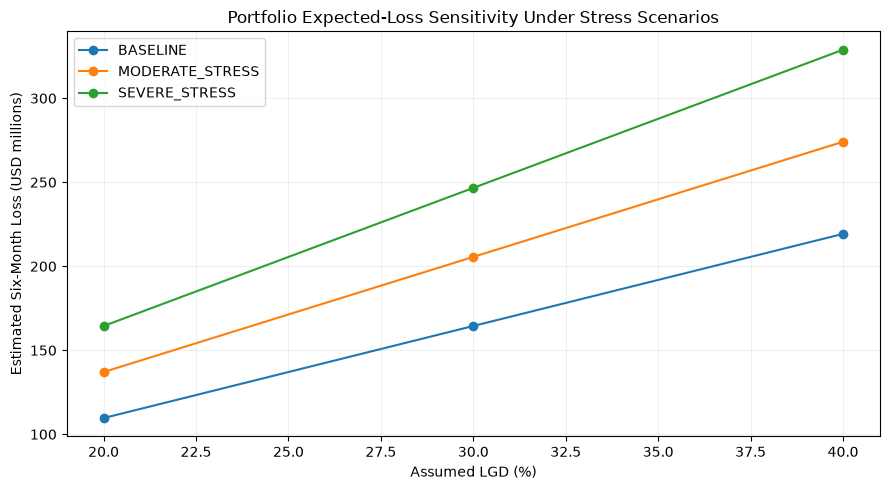

CHART SAVED: True
CHART PATH: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\figures\portfolio\portfolio_stress_sensitivity.png


In [37]:
# ============================================================
# SECTION 17B: SAVE STRESS SCENARIO CHART
# ============================================================

import matplotlib.pyplot as plt

PORTFOLIO_FIGURES_DIR = PROJECT_DIR / "figures" / "portfolio"
PORTFOLIO_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))

for scenario in stress_results["scenario"].unique():

    subset = stress_results[
        stress_results["scenario"] == scenario
    ].sort_values("lgd")

    plt.plot(
        subset["lgd"] * 100,
        subset["estimated_six_month_loss"] / 1e6,
        marker="o",
        label=scenario
    )

plt.xlabel("Assumed LGD (%)")
plt.ylabel("Estimated Six-Month Loss (USD millions)")
plt.title("Portfolio Expected-Loss Sensitivity Under Stress Scenarios")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

CHART_FILE = (
    PORTFOLIO_FIGURES_DIR /
    "portfolio_stress_sensitivity.png"
)

plt.savefig(
    CHART_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("CHART SAVED:", CHART_FILE.exists())
print("CHART PATH:", CHART_FILE)


## 18. Expected-Loss Contribution by EWS Category

This section decomposes the illustrative baseline six-month expected loss across the corrected borrower warning categories.

The analysis uses:
- September 2025 outstanding UPB.
- Validation-fitted sigmoid-calibrated six-month probabilities.
- A common assumed LGD of 30%.

For each warning category, the analysis estimates exposure, average calibrated probability and expected-loss contribution.

This decomposition identifies where model-implied portfolio risk is concentrated. It does not establish realised loss or causal effects.


In [38]:
# ============================================================
# SECTION 18A: EXPECTED-LOSS CONTRIBUTION BY WARNING STATE
# ============================================================

import duckdb
import json

EWS_EL_FILE = (
    PORTFOLIO_DIR /
    "expected_loss_by_ews_state.csv"
)

with open(CALIBRATOR_FILE, "r", encoding="utf-8") as f:
    calibration_parameters = json.load(f)

a = calibration_parameters["slope"]
b = calibration_parameters["intercept"]
eps = calibration_parameters["epsilon"]

LGD_ASSUMPTION = 0.30

calibrated_pd_sql = f"""
1.0 / (
    1.0 + EXP(
        -(
            ({a:.17g}) *
            LN(
                GREATEST(
                    LEAST(t.predicted_probability, {1-eps:.17g}),
                    {eps:.17g}
                )
                /
                (
                    1.0 -
                    GREATEST(
                        LEAST(t.predicted_probability, {1-eps:.17g}),
                        {eps:.17g}
                    )
                )
            )
            + ({b:.17g})
        )
    )
)
"""

con = duckdb.connect()

ews_expected_loss = con.execute(
    f"""
    WITH snapshot AS (

        SELECT
            t.loan_id,
            t.target_6m,
            t.warning_flag_058,
            f.current_actual_upb,

            r.previous_month_warning,
            r.has_valid_previous_month,

            {calibrated_pd_sql} AS calibrated_pd,

            CASE

                WHEN t.warning_flag_058 = 1
                 AND r.has_valid_previous_month = 1
                 AND r.previous_month_warning = 1
                THEN 'PERSISTENT_WARNING'

                WHEN t.warning_flag_058 = 1
                 AND r.has_valid_previous_month = 1
                 AND r.previous_month_warning = 0
                THEN 'NEWLY_FLAGGED'

                WHEN t.warning_flag_058 = 1
                 AND r.has_valid_previous_month = 0
                THEN 'FLAGGED_INSUFFICIENT_HISTORY'

                WHEN t.warning_flag_058 = 0
                 AND r.has_valid_previous_month = 1
                 AND r.previous_month_warning = 1
                THEN 'DE_ESCALATED'

                ELSE 'BELOW_THRESHOLD'

            END AS ews_state

        FROM read_parquet(
            '{TEST_RISK_FILE.as_posix()}'
        ) t

        INNER JOIN read_parquet(
            '{TRAJECTORY_FILE.as_posix()}'
        ) r
            ON t.loan_id = r.loan_id
           AND t.reporting_date = r.reporting_date

        INNER JOIN read_parquet(
            '{FINAL_FEATURE_FILE.as_posix()}'
        ) f
            ON t.loan_id = f.loan_id
           AND t.reporting_date = f.reporting_date

        WHERE t.reporting_date = DATE '{SNAPSHOT_DATE}'
          AND f.current_actual_upb IS NOT NULL
          AND f.current_actual_upb >= 0

    ),

    category_loss AS (

        SELECT
            ews_state,
            COUNT(*) AS loan_accounts,

            SUM(current_actual_upb)
                AS outstanding_upb,

            AVG(calibrated_pd)
                AS average_calibrated_pd,

            AVG(target_6m)
                AS observed_event_rate,

            SUM(
                current_actual_upb *
                calibrated_pd *
                {LGD_ASSUMPTION}
            ) AS estimated_six_month_loss

        FROM snapshot
        GROUP BY ews_state

    )

    SELECT
        *,

        estimated_six_month_loss /
        NULLIF(
            SUM(estimated_six_month_loss) OVER (),
            0
        ) AS share_of_estimated_portfolio_loss

    FROM category_loss
    ORDER BY estimated_six_month_loss DESC
    """
).fetchdf()

con.close()

display(ews_expected_loss.round(6))

ews_expected_loss.to_csv(
    EWS_EL_FILE,
    index=False
)

print("EXPECTED-LOSS CATEGORY ANALYSIS SAVED")
print(EWS_EL_FILE)

assert len(ews_expected_loss) == 5
assert ews_expected_loss["loan_accounts"].sum() == 111141

print("ACCOUNT RECONCILIATION: PASS")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,ews_state,loan_accounts,outstanding_upb,average_calibrated_pd,observed_event_rate,estimated_six_month_loss,share_of_estimated_portfolio_loss
0,BELOW_THRESHOLD,103985,1.567024e+10,0.016478,0.015781,8.114617e+07,0.493412
1,PERSISTENT_WARNING,5801,1.079510e+09,0.192905,0.229616,6.171349e+07,0.375251
2,FLAGGED_INSUFFICIENT_HISTORY,812,1.422013e+08,0.463687,0.597291,1.975713e+07,0.120134
3,DE_ESCALATED,397,6.396681e+07,0.057255,0.161209,1.113900e+06,0.006773
4,NEWLY_FLAGGED,146,2.550262e+07,0.095381,0.061644,7.287340e+05,0.004431


EXPECTED-LOSS CATEGORY ANALYSIS SAVED
C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\data\processed\dynamic_risk\portfolio\expected_loss_by_ews_state.csv
ACCOUNT RECONCILIATION: PASS


In [39]:
# ============================================================
# SECTION 18B: EXPECTED-LOSS RECONCILIATION
# ============================================================

category_total_loss = ews_expected_loss[
    "estimated_six_month_loss"
].sum()

baseline_30_lgd_loss = stress_results.loc[
    (stress_results["scenario"] == "BASELINE") &
    (stress_results["lgd"] == 0.30),
    "estimated_six_month_loss"
].iloc[0]

difference = abs(
    category_total_loss - baseline_30_lgd_loss
)

print("CATEGORY LOSS TOTAL:", category_total_loss)
print("BASELINE STRESS LOSS:", baseline_30_lgd_loss)
print("ABSOLUTE DIFFERENCE:", difference)

assert np.isclose(
    category_total_loss,
    baseline_30_lgd_loss,
    rtol=1e-6,
    atol=1e-4
)

print("\nEXPECTED-LOSS RECONCILIATION: PASS")

CATEGORY LOSS TOTAL: 164459418.4452814
BASELINE STRESS LOSS: 164459418.44528145
ABSOLUTE DIFFERENCE: 5.960464477539063e-08

EXPECTED-LOSS RECONCILIATION: PASS
